In [1]:
%%html
<style>
div.optional {
    display: block;
    background-color: #d7e2ff;
    border-color: #d7e2ff;
    border-left: 5px solid #d7e2ff;
    padding: 0.5em;
}
div.advanced {
    display: block;
    background-color: #fff4d7;
    border-color: #fff4d7;
    border-left: 5px solid #fff4d7;
    padding: 0.5em;
}
</style>

In [2]:
import scipy.stats as st
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import pandas as pd
# https://seaborn.pydata.org/
# "Seaborn is a Python data visualization library based on matplotlib. 
# It provides a high-level interface for drawing attractive and informative statistical graphics."
import seaborn as sns
# switch to seaborn figure aesthetic defaults
#sns.set_theme()
sns.set()

# Computational Mathematics

## Probability (and some first steps towards Machine Learning from a probabilistic perspective)

### Simon Warder

- Email s.warder15@imperial.ac.uk
- Teams `@Warder, Simon C`
- Office 4.91 RSM

### Anonymous feedback form

Your feedback is always helpful! If you would like to share any thoughts - e.g. things that worked for you, or things that didn't - you can use this [anonymous feedback form](https://forms.office.com/Pages/ResponsePage.aspx?id=B3WJK4zudUWDC0-CZ8PTB7wCPgYswKVBuRjvHBJCboRURUxRR0kwWTZYWDhMQkhGRlZFVTVKWUpVVC4u).

### Before we start: assessments & AI

- You will encounter a range of assessments with differing AI guidelines: pay attention to information for each assessment, and ask if anything is unclear
- In general, not acceptable to "offload" work to AI
- In particular, not acceptable to upload any assignment, or constituent parts, to AI
- Same goes for course materials, lecture notes, etc

## Learning objectives  <a class="tocSkip">

1. Quick review of some introductory statistics concepts.

2. Introduction of some basic probability and uncertainty concepts.

3. Introduction of some initial data science/machine learning concepts with some optional reading that will take some steps towards ML that will be picked up in your next two modules.

There is a lot of content here - think of this as reference material you can return to as you encounter some of these concepts or techniques in your next two modules on Data Science \& Machine Learning and Deep Learning.

<h1>Table of Contents<span class="tocSkip"></span></h1>
<div class="toc"><ul class="toc-item"><li><span><a href="#Introduction" data-toc-modified-id="Introduction-1"><span class="toc-item-num">1&nbsp;&nbsp;</span>Introduction</a></span></li><li><span><a href="#Statistics" data-toc-modified-id="Statistics-2"><span class="toc-item-num">2&nbsp;&nbsp;</span>Statistics</a></span><ul class="toc-item"><li><span><a href="#Mean,-variance,-standard-deviation,-and-z-score" data-toc-modified-id="Mean,-variance,-standard-deviation,-and-z-score-2.1"><span class="toc-item-num">2.1&nbsp;&nbsp;</span>Mean, variance, standard deviation, and z-score</a></span><ul class="toc-item"><li><span><a href="#Mean-(average)" data-toc-modified-id="Mean-(average)-2.1.1"><span class="toc-item-num">2.1.1&nbsp;&nbsp;</span>Mean (average)</a></span></li><li><span><a href="#Variance" data-toc-modified-id="Variance-2.1.2"><span class="toc-item-num">2.1.2&nbsp;&nbsp;</span>Variance</a></span><ul class="toc-item"><li><span><a href="#Aside---What's-the-link-between-mean-and-variance-with-regression?-...-A-thought-exercise" data-toc-modified-id="Aside---What's-the-link-between-mean-and-variance-with-regression?-...-A-thought-exercise-2.1.2.1"><span class="toc-item-num">2.1.2.1&nbsp;&nbsp;</span>Aside - What's the link between mean and variance with regression? ... A thought exercise</a></span></li></ul></li><li><span><a href="#Standard-deviation" data-toc-modified-id="Standard-deviation-2.1.3"><span class="toc-item-num">2.1.3&nbsp;&nbsp;</span>Standard deviation</a></span><ul class="toc-item"><li><span><a href="#Population-vs-sample-statistics" data-toc-modified-id="Population-vs-sample-statistics-2.1.3.1"><span class="toc-item-num">2.1.3.1&nbsp;&nbsp;</span>Population vs sample statistics</a></span><ul class="toc-item"><li><span><a href="#Aside:-Bessel's-correction-[*]" data-toc-modified-id="Aside:-Bessel's-correction-[*]-2.1.3.1.1"><span class="toc-item-num">2.1.3.1.1&nbsp;&nbsp;</span>Aside: Bessel's correction [*]</a></span></li></ul></li></ul></li><li><span><a href="#Standard-score-(z-score)" data-toc-modified-id="Standard-score-(z-score)-2.1.4"><span class="toc-item-num">2.1.4&nbsp;&nbsp;</span>Standard score (z-score)</a></span></li></ul></li><li><span><a href="#Example:-the-Iris-dataset" data-toc-modified-id="Example:-the-Iris-dataset-2.2"><span class="toc-item-num">2.2&nbsp;&nbsp;</span>Example: the Iris dataset</a></span></li><li><span><a href="#Covariance-and-correlation-coefficient" data-toc-modified-id="Covariance-and-correlation-coefficient-2.3"><span class="toc-item-num">2.3&nbsp;&nbsp;</span>Covariance and correlation coefficient</a></span><ul class="toc-item"><li><span><a href="#Covariance" data-toc-modified-id="Covariance-2.3.1"><span class="toc-item-num">2.3.1&nbsp;&nbsp;</span>Covariance</a></span></li><li><span><a href="#Covariance-matrix" data-toc-modified-id="Covariance-matrix-2.3.2"><span class="toc-item-num">2.3.2&nbsp;&nbsp;</span>Covariance matrix</a></span></li><li><span><a href="#Correlation-coefficient" data-toc-modified-id="Correlation-coefficient-2.3.3"><span class="toc-item-num">2.3.3&nbsp;&nbsp;</span>Correlation coefficient</a></span></li></ul></li><li><span><a href="#Applying-Principal-Component-Analysis-(PCA)-to-the-Iris-Dataset" data-toc-modified-id="Applying-Principal-Component-Analysis-(PCA)-to-the-Iris-Dataset-2.4"><span class="toc-item-num">2.4&nbsp;&nbsp;</span>Applying Principal Component Analysis (PCA) to the Iris Dataset</a></span></li></ul></li><li><span><a href="#Probability-and-Uncertainty" data-toc-modified-id="Probability-and-Uncertainty-3"><span class="toc-item-num">3&nbsp;&nbsp;</span>Probability and Uncertainty</a></span><ul class="toc-item"><li><span><a href="#Random-variables" data-toc-modified-id="Random-variables-3.1"><span class="toc-item-num">3.1&nbsp;&nbsp;</span>Random variables</a></span><ul class="toc-item"><li><span><a href="#More-definitions-(for-reference)" data-toc-modified-id="More-definitions-(for-reference)-3.1.1"><span class="toc-item-num">3.1.1&nbsp;&nbsp;</span>More definitions (for reference)</a></span></li><li><span><a href="#Discrete-and-continuous-random-variables" data-toc-modified-id="Discrete-and-continuous-random-variables-3.1.2"><span class="toc-item-num">3.1.2&nbsp;&nbsp;</span>Discrete and continuous random variables</a></span></li></ul></li><li><span><a href="#Probability" data-toc-modified-id="Probability-3.2"><span class="toc-item-num">3.2&nbsp;&nbsp;</span>Probability</a></span><ul class="toc-item"><li><span><a href="#Properties" data-toc-modified-id="Properties-3.2.1"><span class="toc-item-num">3.2.1&nbsp;&nbsp;</span>Properties</a></span><ul class="toc-item"><li><ul class="toc-item"><li><span><a href="#Aside:-A-note-on-continuous-variables-and-probability-0-or-1;-&quot;almost-...&quot;-[*]" data-toc-modified-id="Aside:-A-note-on-continuous-variables-and-probability-0-or-1;-&quot;almost-...&quot;-[*]-3.2.1.0.1"><span class="toc-item-num">3.2.1.0.1&nbsp;&nbsp;</span>Aside: A note on continuous variables and probability 0 or 1; "almost ..." [*]</a></span></li></ul></li></ul></li><li><span><a href="#Notation" data-toc-modified-id="Notation-3.2.2"><span class="toc-item-num">3.2.2&nbsp;&nbsp;</span>Notation</a></span></li></ul></li><li><span><a href="#Probability-Distribution-Function" data-toc-modified-id="Probability-Distribution-Function-3.3"><span class="toc-item-num">3.3&nbsp;&nbsp;</span>Probability Distribution Function</a></span><ul class="toc-item"><li><span><a href="#Probability-Mass-Functions" data-toc-modified-id="Probability-Mass-Functions-3.3.1"><span class="toc-item-num">3.3.1&nbsp;&nbsp;</span>Probability Mass Functions</a></span></li><li><span><a href="#Properties-of-Probability-Mass-Functions" data-toc-modified-id="Properties-of-Probability-Mass-Functions-3.3.2"><span class="toc-item-num">3.3.2&nbsp;&nbsp;</span>Properties of Probability Mass Functions</a></span></li><li><span><a href="#Simulation-of-a-die-rolling-experiment" data-toc-modified-id="Simulation-of-a-die-rolling-experiment-3.3.3"><span class="toc-item-num">3.3.3&nbsp;&nbsp;</span>Simulation of a die-rolling experiment</a></span></li><li><span><a href="#Probability-Density-Functions" data-toc-modified-id="Probability-Density-Functions-3.3.4"><span class="toc-item-num">3.3.4&nbsp;&nbsp;</span>Probability Density Functions</a></span><ul class="toc-item"><li><ul class="toc-item"><li><span><a href="#Aside" data-toc-modified-id="Aside-3.3.4.0.1"><span class="toc-item-num">3.3.4.0.1&nbsp;&nbsp;</span>Aside</a></span></li></ul></li></ul></li><li><span><a href="#Example-1:-The-Normal-(Gaussian)-Distribution" data-toc-modified-id="Example-1:-The-Normal-(Gaussian)-Distribution-3.3.5"><span class="toc-item-num">3.3.5&nbsp;&nbsp;</span>Example 1: The Normal (Gaussian) Distribution</a></span></li><li><span><a href="#Cumulative-Distribution-Function-(CDF)" data-toc-modified-id="Cumulative-Distribution-Function-(CDF)-3.3.6"><span class="toc-item-num">3.3.6&nbsp;&nbsp;</span>Cumulative Distribution Function (CDF)</a></span></li><li><span><a href="#Example-2:-Modelling-the-Iris-Data-with-a-Normal-Distribution" data-toc-modified-id="Example-2:-Modelling-the-Iris-Data-with-a-Normal-Distribution-3.3.7"><span class="toc-item-num">3.3.7&nbsp;&nbsp;</span>Example 2: Modelling the Iris Data with a Normal Distribution</a></span></li></ul></li><li><span><a href="#Central-Limit-Theorem-[*]" data-toc-modified-id="Central-Limit-Theorem-[*]-3.4"><span class="toc-item-num">3.4&nbsp;&nbsp;</span>Central Limit Theorem [*]</a></span></li><li><span><a href="#Joint-and-Conditional-Probabilities-(brief-overview---see-supp-material)" data-toc-modified-id="Joint-and-Conditional-Probabilities-(brief-overview---see-supp-material)-3.5"><span class="toc-item-num">3.5&nbsp;&nbsp;</span>Joint and Conditional Probabilities (brief overview - see supp material)</a></span><ul class="toc-item"><li><span><a href="#Joint-Probability" data-toc-modified-id="Joint-Probability-3.5.1"><span class="toc-item-num">3.5.1&nbsp;&nbsp;</span>Joint Probability</a></span></li><li><span><a href="#Marginal-Probability-(Sum-Rule)" data-toc-modified-id="Marginal-Probability-(Sum-Rule)-3.5.2"><span class="toc-item-num">3.5.2&nbsp;&nbsp;</span>Marginal Probability (Sum Rule)</a></span></li><li><span><a href="#Conditional-Probability" data-toc-modified-id="Conditional-Probability-3.5.3"><span class="toc-item-num">3.5.3&nbsp;&nbsp;</span>Conditional Probability</a></span></li><li><span><a href="#The-Product-Rule-(Connecting-Joint-and-Conditional)" data-toc-modified-id="The-Product-Rule-(Connecting-Joint-and-Conditional)-3.5.4"><span class="toc-item-num">3.5.4&nbsp;&nbsp;</span>The Product Rule (Connecting Joint and Conditional)</a></span></li></ul></li></ul></li><li><span><a href="#Machine-Learning,-Data-Science---&quot;simple&quot;-methods-and-links-to-probability" data-toc-modified-id="Machine-Learning,-Data-Science---&quot;simple&quot;-methods-and-links-to-probability-4"><span class="toc-item-num">4&nbsp;&nbsp;</span>Machine Learning, Data Science - "simple" methods and links to probability</a></span><ul class="toc-item"><li><span><a href="#Some-initial-definitions" data-toc-modified-id="Some-initial-definitions-4.1"><span class="toc-item-num">4.1&nbsp;&nbsp;</span>Some initial definitions</a></span></li><li><span><a href="#Data" data-toc-modified-id="Data-4.2"><span class="toc-item-num">4.2&nbsp;&nbsp;</span>Data</a></span><ul class="toc-item"><li><span><a href="#Qualitative-data" data-toc-modified-id="Qualitative-data-4.2.1"><span class="toc-item-num">4.2.1&nbsp;&nbsp;</span>Qualitative data</a></span></li><li><span><a href="#Quantitative-data" data-toc-modified-id="Quantitative-data-4.2.2"><span class="toc-item-num">4.2.2&nbsp;&nbsp;</span>Quantitative data</a></span></li></ul></li><li><span><a href="#Supervised-learning-(classification-|-regression)" data-toc-modified-id="Supervised-learning-(classification-|-regression)-4.3"><span class="toc-item-num">4.3&nbsp;&nbsp;</span>Supervised learning (classification | regression)</a></span></li><li><span><a href="#Bayes'-Theorem" data-toc-modified-id="Bayes'-Theorem-4.4"><span class="toc-item-num">4.4&nbsp;&nbsp;</span>Bayes' Theorem</a></span></li><li><span><a href="#Naive-Bayes-classifier" data-toc-modified-id="Naive-Bayes-classifier-4.5"><span class="toc-item-num">4.5&nbsp;&nbsp;</span>Naive Bayes classifier</a></span><ul class="toc-item"><li><span><a href="#Applying-Naive-Bayes-Classifier-to-the-Iris-Dataset" data-toc-modified-id="Applying-Naive-Bayes-Classifier-to-the-Iris-Dataset-4.5.1"><span class="toc-item-num">4.5.1&nbsp;&nbsp;</span>Applying Naive Bayes Classifier to the Iris Dataset</a></span></li><li><span><a href="#Accuracy-of-our-classifier" data-toc-modified-id="Accuracy-of-our-classifier-4.5.2"><span class="toc-item-num">4.5.2&nbsp;&nbsp;</span>Accuracy of our classifier</a></span></li></ul></li><li><span><a href="#Likelihood-and-Maximum-Likelihood-Estimation-(MLE)-[*]" data-toc-modified-id="Likelihood-and-Maximum-Likelihood-Estimation-(MLE)-[*]-4.6"><span class="toc-item-num">4.6&nbsp;&nbsp;</span>Likelihood and Maximum Likelihood Estimation (MLE) [*]</a></span><ul class="toc-item"><li><span><a href="#The-(negative)-log-likelihood--[*]" data-toc-modified-id="The-(negative)-log-likelihood--[*]-4.6.1"><span class="toc-item-num">4.6.1&nbsp;&nbsp;</span>The (negative) log likelihood  [*]</a></span></li><li><span><a href="#Maximum-likelihood-estimation-(MLE)--[*]" data-toc-modified-id="Maximum-likelihood-estimation-(MLE)--[*]-4.6.2"><span class="toc-item-num">4.6.2&nbsp;&nbsp;</span>Maximum likelihood estimation (MLE)  [*]</a></span></li><li><span><a href="#Example-[**]" data-toc-modified-id="Example-[**]-4.6.3"><span class="toc-item-num">4.6.3&nbsp;&nbsp;</span>Example [**]</a></span></li></ul></li><li><span><a href="#Maximum-a-posteriori-estimation-(MAP;-the-Bayesian-alternative-to-MLE)-[**]" data-toc-modified-id="Maximum-a-posteriori-estimation-(MAP;-the-Bayesian-alternative-to-MLE)-[**]-4.7"><span class="toc-item-num">4.7&nbsp;&nbsp;</span>Maximum a posteriori estimation (MAP; the Bayesian alternative to MLE) [**]</a></span></li><li><span><a href="#Revisiting-linear-regression-from-a-probabilistic-perspective-[*]" data-toc-modified-id="Revisiting-linear-regression-from-a-probabilistic-perspective-[*]-4.8"><span class="toc-item-num">4.8&nbsp;&nbsp;</span>Revisiting linear regression from a probabilistic perspective [*]</a></span><ul class="toc-item"><li><span><a href="#Maximum-likelihood-estimation-for-linear-regression-[**]" data-toc-modified-id="Maximum-likelihood-estimation-for-linear-regression-[**]-4.8.1"><span class="toc-item-num">4.8.1&nbsp;&nbsp;</span>Maximum likelihood estimation for linear regression [**]</a></span></li><li><span><a href="#Linear-regression-on-the-Iris-dataset-[**]" data-toc-modified-id="Linear-regression-on-the-Iris-dataset-[**]-4.8.2"><span class="toc-item-num">4.8.2&nbsp;&nbsp;</span>Linear regression on the Iris dataset [**]</a></span><ul class="toc-item"><li><ul class="toc-item"><li><span><a href="#Warning" data-toc-modified-id="Warning-4.8.2.0.1"><span class="toc-item-num">4.8.2.0.1&nbsp;&nbsp;</span>Warning</a></span></li></ul></li></ul></li><li><span><a href="#Exercise" data-toc-modified-id="Exercise-4.8.3"><span class="toc-item-num">4.8.3&nbsp;&nbsp;</span>Exercise</a></span></li></ul></li><li><span><a href="#Back-to-classification-(via-logistic-regression)-[*]" data-toc-modified-id="Back-to-classification-(via-logistic-regression)-[*]-4.9"><span class="toc-item-num">4.9&nbsp;&nbsp;</span>Back to classification (via logistic regression) [*]</a></span><ul class="toc-item"><li><span><a href="#Classification-via-logistic-regression-[*]" data-toc-modified-id="Classification-via-logistic-regression-[*]-4.9.1"><span class="toc-item-num">4.9.1&nbsp;&nbsp;</span>Classification via logistic regression [*]</a></span></li><li><span><a href="#Sigmoid-functions-...-the-logistic-function-[*]" data-toc-modified-id="Sigmoid-functions-...-the-logistic-function-[*]-4.9.2"><span class="toc-item-num">4.9.2&nbsp;&nbsp;</span>Sigmoid functions ... the logistic function [*]</a></span></li><li><span><a href="#Classification-using-the-logistic-function-and-linear-regression-[*]" data-toc-modified-id="Classification-using-the-logistic-function-and-linear-regression-[*]-4.9.3"><span class="toc-item-num">4.9.3&nbsp;&nbsp;</span>Classification using the logistic function and linear regression [*]</a></span></li><li><span><a href="#Interpretation-as-a-simple-neural-network" data-toc-modified-id="Interpretation-as-a-simple-neural-network-4.9.4"><span class="toc-item-num">4.9.4&nbsp;&nbsp;</span>Interpretation as a simple neural network</a></span></li><li><span><a href="#Comparison-between-Logistic-Regression-and-Naive-Bayes-[*]" data-toc-modified-id="Comparison-between-Logistic-Regression-and-Naive-Bayes-[*]-4.9.5"><span class="toc-item-num">4.9.5&nbsp;&nbsp;</span>Comparison between Logistic Regression and Naive Bayes [*]</a></span></li><li><span><a href="#An-example--[**]" data-toc-modified-id="An-example--[**]-4.9.6"><span class="toc-item-num">4.9.6&nbsp;&nbsp;</span>An example  [**]</a></span></li></ul></li><li><span><a href="#Other-classification-and-regression-models" data-toc-modified-id="Other-classification-and-regression-models-4.10"><span class="toc-item-num">4.10&nbsp;&nbsp;</span>Other classification and regression models</a></span></li></ul></li><li><span><a href="#Summary" data-toc-modified-id="Summary-5"><span class="toc-item-num">5&nbsp;&nbsp;</span>Summary</a></span></li></ul></div>

# Introduction

In science, data science, and machine learning, we're always dealing with data – from experiments, observations, or computer simulations. 
In previous lectures we've seen how **linear algebra** helps us handle this data, especially when it has many features, and how techniques like **regression** let us model relationships within it. 
But data isn't perfect; it has noise, our models have limits, and many systems have inherent randomness. 
How do we make sense of things and make decisions when faced with this **uncertainty**? That's where **probability** and **statistics** come in.

*Data science* and *machine learning* aim to find patterns and learn from data. Building models based on observations is standard practice in science. We've touched on this modelling idea before, and it's always worth remembering:

> "All models are wrong, some are useful" - George Box

### Where does uncertainty come from? <a class="tocSkip"></a>

To build useful models and interpret data correctly, we need to handle uncertainty. Probability gives us the mathematical tools to do this. Uncertainty can pop up from various places:

* The data itself might be noisy or contain errors.
* We might not have all the data we need (incomplete information).
* The system we're studying might be naturally random (stochastic*).
* Our models might be simplified versions of reality (model inadequacy).

[* "Although stochasticity and randomness are distinct in that the former refers to a modelling approach and the latter refers to phenomena themselves, these two terms are often used synonymously <https://en.wikipedia.org/wiki/Stochastic>."]

Probability helps us quantify this uncertainty. It allows us to build models that not only make predictions but also tell us how confident we are in those predictions. This is crucial for the **Data Science & Machine Learning** and **Deep Learning** modules coming up next.

**Types of Uncertainty:**

It's helpful to know about two main kinds of uncertainty:

* [**Aleatoric**](https://en.wikipedia.org/wiki/Uncertainty_quantification#Aleatoric_and_epistemic_uncertainty): This is the uncertainty from pure randomness that we *can't* reduce, even with more data or a better model. Think about rolling a fair die – you can't know the exact outcome of the *next* roll, no matter how much you know about the die.

***Aleatoric*** is roughly about "***randomness***" or uncertainty you can't get rid of.

* [**Epistemic**](https://en.wikipedia.org/wiki/Uncertainty_quantification#Aleatoric_and_epistemic_uncertainty): This uncertainty comes from our *lack of knowledge* – maybe our model isn't perfect, or our measurements aren't precise enough. We *can* reduce this type by getting more data, improving the model, or taking better measurements. Think about predicting the weather – a better forecast model or more sensor data *could* make the prediction more accurate.

***Epistemic*** is roughly about a "***lack of knowledge***" or uncertainty you potentially *can* reduce.

Suggested further reading:

* Tony O'Hagan, Dicing with the unknown. <https://rss.onlinelibrary.wiley.com/doi/full/10.1111/j.1740-9713.2004.00050.x> (Goes into these ideas in more detail).

[NB. This connects back to our earlier talks about model validation, checking sensitivity to inputs, and figuring out uncertain parameters.]

**Some background reading on definitions**

Probability uses models to predict future event likelihoods; statistics uses past data to understand the process or model that created it.

* What's the difference between probability and statistics? <https://stats.stackexchange.com/questions/665/whats-the-difference-between-probability-and-statistics>

**Probability asks: "Given this model, what data should I expect?" Statistics asks: "Given this data, what model likely produced it?".**

# Statistics

First let's quickly get through a review of some concepts from introductory statistics.

Statistics gives us tools to describe and summarise data. These summary values help us understand the main features of a dataset, like its central point and how spread out the data points are....

## Mean, variance, standard deviation, and z-score

Suppose we have a set of values (*dataset*) 

$$\{x_1, x_2, \ldots, x_n\}$$ 

that have been obtained by measuring/observing a property of some system we want to understand. For instance, $x_i$ could be the prices of houses in London, or blood pressure readings of patients in a medical trial studying the effectiveness of a new treatment. 

We can write our one-dimensional dataset as a vector 

$$\mathbf{x} = [x_1, x_2, \ldots, x_n]^T$$ 

The size of the dataset $n$ can range from only a few to many billions.  Looking at the values one by one trying to find patterns in the data would most probably not lead us to a useful understanding of the system. We need summary statistics.

What first statistical values can we extract from our dataset to help us start to better understand the system (via the data)?

(Note: The following definitions assume our dataset  $\{x_1, x_2, \ldots, x_n\}$ represents the entire population we are interested in. We'll discuss the difference between population and samples shortly.)

### Mean (average)

The *mean* of a vector $\mathbf{x} = [x_1, x_2, \ldots, x_n]^T$, usually denoted as $\bar{x}$, is typically taken to be the **arithmetic mean** (average) of its elements, i.e. the sum of its components $x_i$ divided by the number of components $n$: 

$$
\bar{x} = \frac{1}{n} \sum_{i=1}^n x_i
$$

We interpret the mean as the middle (or the central point) of our dataset around which all values are equally distributed.

Note: There are other "means" such as the *harmonic mean* ($HM$) and the *geometric mean* ($GM$), but when we use *mean* with no qualifiers, we are typically referring to the *arithmetic mean* ($AM$) as above. 

Together these are termed the three classical [*Pythagorean means*](https://en.wikipedia.org/wiki/Pythagorean_means). 

Similar to what we observed for norms in L4, there is an ordering of their magnitudes (in the case that the $x$ data are all positive) ($HM\le GM \le AM$)

NB. The *median* and the *mode* are other examples of [*averages*](https://en.wikipedia.org/wiki/Average).

In [63]:
# We can use np.mean to find the arithmetic mean:

# datasets
x = np.array([-15, 1, 9, 25])
y = np.array([3, 4, 6, 7])

# (arithmetic) means of these two datasets
print('mean(x) = {}'.format(np.mean(x)))
print('mean(y) = {}'.format(np.mean(y)))

# For the geometric and harmonic means, and checking the comment on ordering for positive data (hence use of y data)
import scipy.stats as st # Ensure st is imported if not already
print('\n Pythagorean means of y (Harmonic, Geometric, Arithmetic): ', st.hmean(y), st.gmean(y), np.mean(y)) 

mean(x) = 5.0
mean(y) = 5.0

 Pythagorean means of y (Harmonic, Geometric, Arithmetic):  4.48 4.738137220537587 5.0


### Variance

The [*variance*](https://en.wikipedia.org/wiki/Variance), or to be precise, the *population variance*, is a value describing how the data is spread around the centre of our data (mean). 

* A **large variance** means data points are far from the mean.
* A **small variance** means data points are clustered closely around the mean.

For example, datasets $\mathbf{x} = [-15, 1, 9, 25]^T$ and $\mathbf{y} = [3, 4, 6, 7]^T$ both have a mean of 5, but the values in $\mathbf{x}$ are more spread out than in $\mathbf{y}$. So, $\mathbf{x}$ has a higher variance.

We calculate the population variance, $\mathrm{Var}(\mathbf{x})$, by averaging the squared distances of each data point from the mean:

$$\mathrm{Var}(\mathbf{x}) = \frac{1}{n}\sum_{i=1}^n (x_i - \bar{x})^2$$

**Aside:**

For discussions on why we take the square  of the differences see <https://stats.stackexchange.com/questions/118/why-square-the-difference-instead-of-taking-the-absolute-value-in-standard-devia> and comments on the potential advantages of just taking the absolute mean difference: <https://onlinelibrary.wiley.com/doi/abs/10.1111/j.1467-8527.2005.00304.x>.

Note the overlap with discussions over RMSE vs MAE!

In [64]:
# datasets
x = np.array([-15, 1, 9, 25])
y = np.array([3, 4, 6, 7])

# Variances
print('Var(x) = {}'.format(np.var(x)))
print('Var(y) = {}'.format(np.var(y)))

Var(x) = 208.0
Var(y) = 2.5


#### Aside - What's the link between mean and variance with regression? ... A thought exercise

Thought exercise: If we start from our dataset and seek to perform least-squares based curve-fitting or regression using a constant function, what are other words for the value of our approximating function and the corresponding mean square error that is being minimised in the least-squares approach?

In [5]:
# Consider our dataset
x = np.array([-15, 1, 9, 25])

# Re-use code from L5 to fit a degree zero polynomial (a constant) to the data
degree = 0
# we need two vectors, assume our data (variable x) has corresponding "x" data just given by 0,1,2,3 
# - result not dependent on this choice 
poly_coeffs = np.polyfit(np.arange(len(x)), x, degree)
print('poly_coeffs: ',poly_coeffs)

def sqr_error(p, xi, yi):
    """function to evaluate the sum of square of errors"""
    # first compute the square of the differences
    diff2 = (p(xi)-yi)**2
    # and return their sum
    return diff2.sum()

p = np.poly1d(poly_coeffs)
print('square of the difference between the data and the '
          'polynomial of degree 0 = ',sqr_error(p, np.arange(4), x))
print('and so the average of the squares of the errors is ',sqr_error(p, np.arange(4), x)/len(x))

poly_coeffs:  [5.]
square of the difference between the data and the polynomial of degree 0 =  832.0
and so the average of the squares of the errors is  208.0


What does this show us? 

The "best fit" 0-degree polynomial (a constant line) is simply the mean of the data. We see this as the poly_coeffs value (5.; corresponding to the zero-eth power of x or constant term in the degree zero polynomial) is the mean we calculated earlier. 

More importantly, the 'average of the squares of the errors' (208.0) is the variance of the data. In summary:

- The Mean is the single best value to represent a dataset, in a least-squares sense.

- The Variance is the mean squared error of that "model," telling us how good (or bad) that single-value representation is.

This shows how even basic statistics relate to the core ideas of modelling and measuring error that we use in regression and machine learning.

### Standard deviation

The *standard deviation* (or more precisely the *population* SD) is simply the square root of the variance. It is usually denoted as $\sigma$:

$$
\sigma(x) = \sqrt{\mathrm{Var}(\mathbf{x})} = \sqrt{\frac{1}{n}\sum_{i=1}^n (x_i - \bar{x})^2}
$$

Both the variance and the standard deviation are *dispersion indicators*: they quantify how the values in a dataset are dispersed around the mean. 

Note that the **units (or dimension)** of variance is the square of the units of the observations, whereas the standard deviation has the same units making it arguably more interpretable. 

Both the variance and the standard deviation are always non-negative (like a distance, measuring how far away the data points are from the mean):

$$
\mathrm{Var}(x) \geq 0, \quad \sigma(x) \geq 0
$$

Aside: Recall that we made a similar observation when commenting on the mean square error (MSE) vs the root mean square error (RMSE). We don't need to take square roots (redundant flops), nor indeed take the average, when minimising using this quantity within an algorithm, but we may want to ultimately average and take square roots when reporting or comparing methods.

In [65]:
# datasets
x = np.array([-15, 1, 9, 25])
y = np.array([3, 4, 6, 7])

# standard deviations
print('std_dev(x) = {}'.format(np.std(x)))
print('std_dev(y) = {}'.format(np.std(y)))

# Check relationship (using sample versions from st - see next section)
print(np.isclose(st.tstd(x)**2,st.tvar(x))) 

std_dev(x) = 14.422205101855956
std_dev(y) = 1.5811388300841898
True


### Population vs sample statistics

It's important to distinguish between a **population** (the entire group we're interested in, e.g., *all* houses in London) and a **sample** (a subset of the population we actually have data for, e.g., prices of 1000 houses in London).

The definitions for mean, variance, and standard deviation above ($\bar{x}$, $\mathrm{Var}(\mathbf{x})$, $\sigma(\mathbf{x})$ with division by $n$) are for calculating these values *if our dataset $\mathbf{x}$ represents the entire population*.

Getting data for the entire population is often difficult, if not impossible. 
More commonly, we work with a *sample* from a large population, which is a subset of the whole population, and we want to use this sample to **estimate** the mean, variance, or standard deviation of the whole **population**.

In this case, we are interested in using the data from the *sample* to estimate the mean/variance of the *population*. 

* The **sample mean** ($\bar{x} = \frac{1}{n} \sum x_i$) is a good [*unbiased estimator*](https://en.wikipedia.org/wiki/Bias_of_an_estimator) of the population mean. On average, the sample mean will give you the true population mean.

* However, the **sample variance** (and standard deviation) calculated using $\frac{1}{n}\sum (x_i - \bar{x})^2$ tends to be *smaller* than the true population variance. It is thus a **biased** estimator.

Hence, we must make a distinction between calculating the population variance directly and using the sample variance to *estimate* population variance. 

NB. The sample mean/variance can also be referred to as the empirical mean/variance ("empirical" meaning based on observation(s)).

From <https://en.wikipedia.org/wiki/Bessel%27s_correction>

>"The sum of squares of the distance from samples to the population mean will always be bigger than the sum of squares of the distance to the sample mean, except when the sample mean happens to be the same as the population mean, in which case the two are equal....
That is why the sum of squares of the deviations from the sample mean is too small to give an unbiased estimate of the population variance when the average of those squares is found. The smaller the sample size, the larger is the difference between the sample variance and the population variance."

A way to see this

Consider our dataset and assume this is the entire population

$$\mathbf{y} = [3, 4, 6, 7]^T$$ 

with mean 5 and variance 2.5.

Now take the first entry only as our sample, its mean is 3 and its variance (using this same sample mean in the calculation) is 0. 

Take the final entry of $y$ as our sample, ... mean 7, variance again 0.

So these samples give arguably reasonable, and unbiased estimates of the pop mean, but the variance (calculated using the sample mean which is all we may know) is always biased in being too low.

##### Bessel's correction

To get an **unbiased estimate** of the **population variance** *from a sample*, we use a [correction](https://en.wikipedia.org/wiki/Bessel%27s_correction).: we divide by $n-1$ instead of $n$:

$$s^2 = \frac{1}{n-1}\sum_{i=1}^n (x_i - \bar{x})^2$$

Here, $s^2$ is the **sample variance** (an unbiased estimator of the population variance $\sigma^2$). The corresponding **sample standard deviation** is its square root.

Dividing by the slightly smaller $n-1$ makes the estimate a bit larger, correcting for the tendency of the $\frac{1}{n}$ version to underestimate the population variance.
    
Note that when $n$ is large, the difference between $n$ and $n-1$ is small.

<div class="optional">

##### More on Bessel's correction [\*]

<br>
See also 

- <https://en.wikipedia.org/wiki/Unbiased_estimation_of_standard_deviation>

- <https://en.wikipedia.org/wiki/Variance#Sample_variance>

And as this concept might be a bit hard to get your head around and easily misunderstood see also discussions (which also confuse the issue by, for example, also using an assumed population mean in the sample variance calculation):

- <https://math.stackexchange.com/questions/3270153/is-sample-variance-always-less-than-or-equal-to-population-variance>

- <https://www.quora.com/Why-is-the-sample-variance-always-smaller-than-the-population-variance>
    
<br>
    
    
**Key Point:** Be aware of whether a formula or function uses $n$ or $n-1$. When $n$ is large, the difference is small. Libraries often provide options for both.

* `numpy.var()` and `numpy.std()` calculate the **population** variance/std dev by default (using $n$). They have an optional `ddof` (delta degrees of freedom) argument; setting `ddof=1` makes them use $n-1$.
* `scipy.stats.tvar()` and `scipy.stats.tstd()` (and often Pandas methods) calculate the **sample** variance/std dev by default (using $n-1$).

Let's check this:

</div>

In [7]:
x = np.array([-15, 1, 9, 25])
n = len(x)

# from scipy stats library, use the trimmed SD and VAR functions (we're not doing any trimming)
print('std_dev(x) = {}'.format(st.tstd(x)))
print('var(x) = {}'.format(st.tvar(x)))

# is this SD the square root of variance?
print(np.isclose(st.tstd(x)**2,st.tvar(x)))
# yes they are - so these two functions agree with our definitions

# Now, are our variances from numpy computed above and using scipy.stats the same?
print(np.isclose(np.var(x), st.tvar(x)))
# no they're not

# How can we reconcile this difference? -----> let's try undoing the Bessel correction:
print(np.isclose(np.var(x), ((n-1)/n) * st.tvar(x)))


# note that we can get the sample variance from numpy using optional argument
# np.var(x, ddof=1) # Divides by n-1
# See https://numpy.org/devdocs/reference/generated/numpy.var.html

std_dev(x) = 16.65332799572906
var(x) = 277.3333333333333
True
False
True


### Standard score (z-score)

By knowing how to compute the mean ($\bar{x}$) and the standard deviation ($\sigma$), we can now define the [*standard score*](https://en.wikipedia.org/wiki/Standard_score), commonly referred to as the z-score, for a data point. 

We can compute the difference between a single value $x_i$ in the dataset $\mathbf{x}$ and the mean as $(x_i - \bar{x})$.

The problem with quoting or analysing differences is that they depend on the units and scale of the data - it's often good practice to make these differences *relative* by somehow normalising, or making non-dimensional.

If we divide our difference by the standard deviation we get the standard score (z-score):

$$z_{i} = \frac{x_i - \bar{x}}{\sigma}$$

### Standard score (z-score) (cont.) <a class="tocSkip"></a>

The z-score has no units (i.e. is dimensionless, this is because we've divided two quantities that have the same units - the reason we use the SD here and not the variance of course).

### Standard score (z-score) (cont.) <a class="tocSkip"></a>

The z-score quantifies how many standard deviations our data point $x_i$ is above (positive score) or below (negative) the mean. 

z-scores are useful for comparing values from different datasets that might have different means and standard deviations, or for identifying outliers.

Let's see how to use scipy to compute z-scores for data points in $\mathbf{x}$ from the previous example (which recall had mean 5 and SD $\sim$14):

In [66]:
x = np.array([-15, 1, 9, 25])
mean_x = np.mean(x)
std_dev_x = np.std(x) # Using population std dev here

print(f"Dataset x: {x}")
print(f"Mean: {mean_x:.2f}, Std Dev: {std_dev_x:.2f}")

# Calculate z-scores manually for comparison
manual_z_scores = (x - mean_x) / std_dev_x
print(f"Manual z-scores: {manual_z_scores}")

# Use scipy.stats.zscore 
scipy_z_scores = st.zscore(x)
print(f"scipy.stats.zscore: {scipy_z_scores}")

Dataset x: [-15   1   9  25]
Mean: 5.00, Std Dev: 14.42
Manual z-scores: [-1.38675049 -0.2773501   0.2773501   1.38675049]
scipy.stats.zscore: [-1.38675049 -0.2773501   0.2773501   1.38675049]


## Example: the Iris dataset

Let's make use of a standard data set to compute some simple statistics, 

(also a bit later we'll use it to perform some simple classification and ML tasks).

The famous [**Iris dataset**](https://en.wikipedia.org/wiki/Iris_flower_data_set) is a multivariate dataset consisting of 150 flowers: **50 samples** from each of the **three species** of the Iris flower (*Iris setosa*, *Iris virginica*, *Iris versicolor*) by botanist Edgar Anderson.

**Four features** were measured for each sample: the length and the width of the sepals and the petals, in centimetres. Based on the combination of these four features, statistician/biologist Ronald Fisher developed a model to distinguish the species from each other.

This data set remained a popular reference data set for classification for many decades following its introduction - to the point that [scikit-learn](https://scikit-learn.org/) (a Python package with implementations of many common data analysis and machine learning algorithms) includes it as one of its "toy" standard datasets <https://scikit-learn.org/stable/datasets/toy_dataset.html>.

However, it is considered *too simple* for today's state-of-the-art deep learning algorithms and hence not really used outside of the classroom anymore. 

In [9]:
# load the Iris data set via scikit-learn

from sklearn.datasets import load_iris

iris = load_iris()

# The loaded object contains data, labels, descriptions etc.
print(iris.keys()) 

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])


### Example: the Iris dataset (cont.) <a class="tocSkip"></a>

Take a look here to see what the resulting scikit-learn "bunch" object iris now contains: <https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_iris.html>

We can look at the description of the Iris dataset to give us a bit of background and context.

In [10]:
print(iris['DESCR'])

.. _iris_dataset:

Iris plants dataset
--------------------

**Data Set Characteristics:**

:Number of Instances: 150 (50 in each of three classes)
:Number of Attributes: 4 numeric, predictive attributes and the class
:Attribute Information:
    - sepal length in cm
    - sepal width in cm
    - petal length in cm
    - petal width in cm
    - class:
            - Iris-Setosa
            - Iris-Versicolour
            - Iris-Virginica

:Summary Statistics:

============== ==== ==== ======= ===== ====================
                Min  Max   Mean    SD   Class Correlation
============== ==== ==== ======= ===== ====================
sepal length:   4.3  7.9   5.84   0.83    0.7826
sepal width:    2.0  4.4   3.05   0.43   -0.4194
petal length:   1.0  6.9   3.76   1.76    0.9490  (high!)
petal width:    0.1  2.5   1.20   0.76    0.9565  (high!)
============== ==== ==== ======= ===== ====================

:Missing Attribute Values: None
:Class Distribution: 33.3% for each of 3 classes.
:Cr

### Example: the Iris dataset (cont.) <a class="tocSkip"></a>

The "data" consists of 150 rows and 4 columns:

In [11]:
# print(iris['data'])  # uncomment to print the 150x4 data

print(iris['data'][:5]) # Print first 5 rows

print(f"Data shape: {iris['data'].shape}")
print(f"Feature names: {iris['feature_names']}")

[[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]]
Data shape: (150, 4)
Feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


### Example: the Iris dataset (cont.) <a class="tocSkip"></a>

The four columns are measurements (in cm) of the following features:

In [12]:
print(iris['feature_names'])

['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


Each data row is a member of one of the three species of Iris. 

### Example: the Iris dataset (cont.) <a class="tocSkip"></a>

We are dealing here with a labelled dataset: the target labels or identifiers (0, 1, or 2) encode to which Iris species (or **class**) each row belongs to:

In [13]:
print(iris['target'])

print(f"Target shape: {iris['target'].shape}")
print(f"Target names (species): {iris['target_names']}") # Mapping 0, 1, 2 to names

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2]
Target shape: (150,)
Target names (species): ['setosa' 'versicolor' 'virginica']


Let's load the Iris dataset into a `pandas` DataFrame:

In [67]:
# Combine features and target labels into a DataFrame
# load the Iris data set via scikit-learn

from sklearn.datasets import load_iris

irisdf = load_iris(as_frame=True)['frame']

# Display the first few rows
irisdf.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


Let's try visualising the data. A **pair plot** shows scatter plots for every pair of features, helping us see relationships and how the classes are distributed. The diagonal shows the distribution of each single feature. 

We make use of the seaborn plotting library:

<https://seaborn.pydata.org/generated/seaborn.pairplot.html>

    `By default, this function will create a grid of Axes such that each numeric variable in data will by shared across the y-axes across a single row and the x-axes across a single column. The diagonal plots are treated differently: a univariate distribution plot is drawn to show the marginal distribution of the data in each column.`

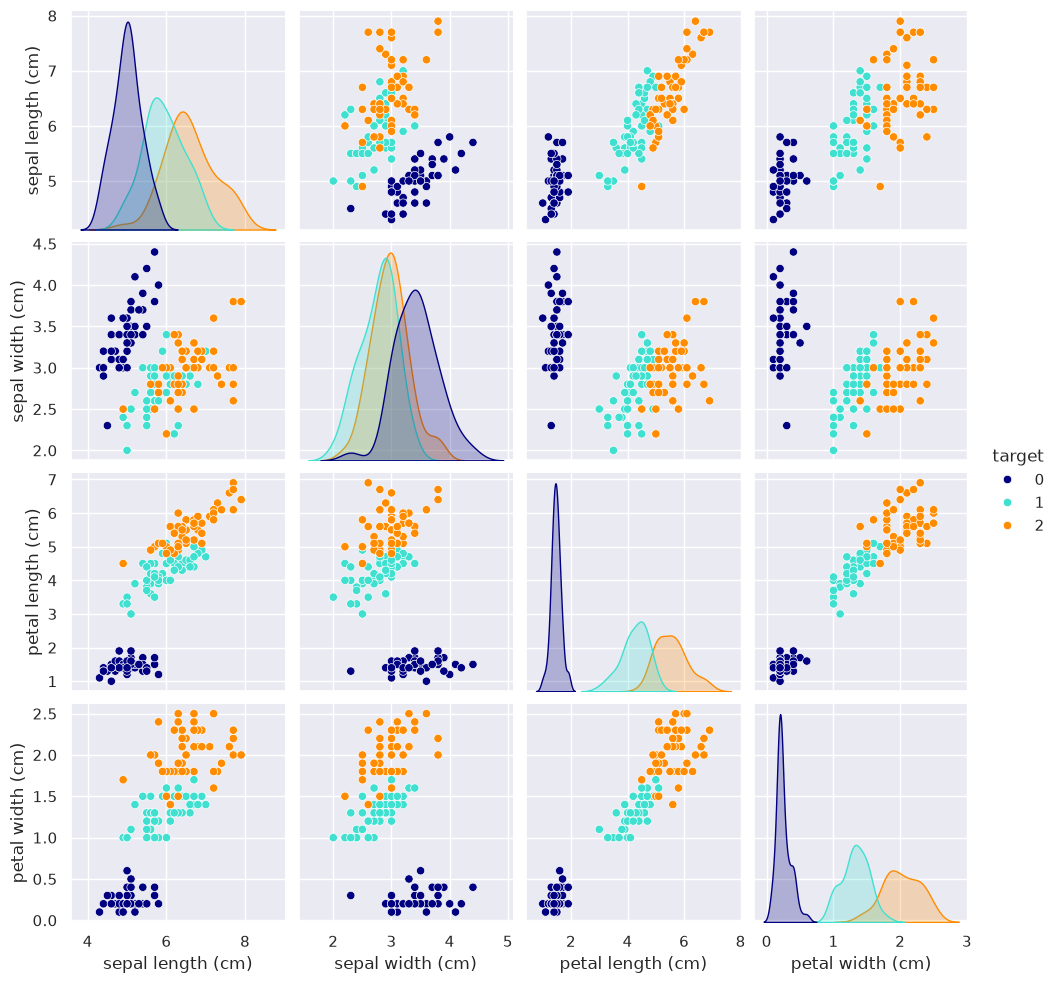

In [68]:
sns.set() # Apply seaborn default styles

# Create a pair plot, coloring points by the 'target' (species) column
# We exclude the 'target' column itself from the pairwise plots (vars=...)
sns.pairplot(irisdf, vars=irisdf.columns[:-1], hue='target',
             palette={0: 'navy', 1: 'turquoise', 2: 'darkorange'}) # Optional: specify colors

### z-scores for the Iris dataset

In [69]:
irisdf_z_scores = irisdf.copy()

for c in irisdf_z_scores.columns:
    if c != 'target':
        irisdf_z_scores[c] = st.zscore(irisdf_z_scores[c])

print(irisdf['sepal length (cm)'].describe())
print(irisdf_z_scores['sepal length (cm)'].describe())
  
# Optional: reproduce the pairplot and see what's changed
# sns.pairplot(irisdf_z_scores, vars=irisdf_z_scores.columns[:-1], hue='target',
#             palette={0: 'navy', 1: 'turquoise', 2: 'darkorange'}) # Optional: specify colors

count    150.000000
mean       5.843333
std        0.828066
min        4.300000
25%        5.100000
50%        5.800000
75%        6.400000
max        7.900000
Name: sepal length (cm), dtype: float64
count    1.500000e+02
mean    -4.736952e-16
std      1.003350e+00
min     -1.870024e+00
25%     -9.006812e-01
50%     -5.250608e-02
75%      6.745011e-01
max      2.492019e+00
Name: sepal length (cm), dtype: float64


## Covariance and correlation coefficient

As we saw in the previous section, the variance of a dataset is computed as the average of the squared distances from the mean ... variance and standard deviation tell us about the spread of a single variable. 

*Covariance* and *correlation* tell us how two variables change together.

### Covariance

The (population) [*covariance*](https://en.wikipedia.org/wiki/Covariance) measures whether high values in one variable tend to occur with high values in another (positive covariance) or with low values in another (negative covariance).

If we have two variables $x$ and $y$ (columns in our dataset), we calculate the covariance by averaging the product of their deviations from their respective means:

$$
\mathrm{Cov}(x, y) = \frac{1}{n}\sum_{i=1}^n (x_i - \bar{x})(y_i - \bar{y}).
$$

Note that, unlike variance, which is always positive, covariance can be both positive or negative.

### Covariance: intuition <a class="tocSkip"></a>

Let's think a bit about what's going on here:

- subtracting the means can be interpreted as shifting all the $x$ and all the $y$ data to be distributed about zero.

- the covariance will then be LARGE in magnitude and POSITIVE when it is made up of a sum of large positive numbers (which we get through the product of two large positive values, OR through the product of two large in magnitude but negative values)

- conversely the covariance will be LARGE in magnitude and NEGATIVE when it is made up of a sum of large in magnitude negative numbers (which we get through the product of two large in magnitude values of differing signs)

- and finally the covariance will be SMALLER in magnitude when larger numbers are multiplied with smaller numbers, and will be zero or near zero when the resulting positives and negatives cancel each other out when summed.

### Covariance: interpretation <a class="tocSkip"></a>

The result is that a positive covariance means that the two variables vary in the same direction: larger values in one variable are associated with larger values in the other, and similarly smaller values in one variable are associated with smaller values in the other. 

On the other hand, a negative covariance means that larger values of one variable are associated with smaller values of the other, and vice-versa. 

Finally, a covariance close to 0 means that there is no linear relationship between the two variables.

### Covariance in the Iris data <a class="tocSkip"></a>

Looking at the plots above (before looking at the numbers from the following cell, use the "eyeball norm" to estimate the covariances in terms of larger/smaller, positive/negative - do this for all the data, i.e. ignore the different colours.

Now let's actually calculate the covariances between the four measured variables in the Iris dataset using the Pandas pairwise covariance function (note that `DataFrame.cov()` divides by $n-1$, i.e. it gives the *sample* covariance - see *Population vs sample statistics* above; with $n=150$ the difference is under 1%):

In [70]:
# Calculate the covariance between pairs of features in the Iris dataset using pandas
# [:, :-1] excludes the 'target' or class column before calculating covariance
irisdf.iloc[:, :-1].cov()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
sepal length (cm),0.685694,-0.042434,1.274315,0.516271
sepal width (cm),-0.042434,0.189979,-0.329656,-0.121639
petal length (cm),1.274315,-0.329656,3.116278,1.295609
petal width (cm),0.516271,-0.121639,1.295609,0.581006


### Covariance matrix

By computing covariances on the Iris dataset, we obtained more than a single value - we obtained a matrix. 

We refer to that matrix as a [*covariance matrix*](https://en.wikipedia.org/wiki/Covariance_matrix). It helps us to visually structure the covariances between two or more variables in a dataset. With $k$ variables in a dataset, the covariance matrix is a $k \times k$ symmetric matrix, as illustrated in [Figure 1](#fig:covariance_matrix). 

### Covariance matrix (cont.) <a class="tocSkip"></a>

<img src="images/ch03_covariance_matrix.png" id="fig:covariance_matrix" width="250" alt="Figure 1: The illustration of a covariance matrix of the variables x and y." />

**Figure 1**: The illustration of a $2 \times 2$ covariance matrix between the variables $x$ and $y$.

### Covariance matrix: diagonal and symmetry <a class="tocSkip"></a>

The diagonal is filled with the covariances of variables with themselves - $\mathrm{Cov}(x, x)$ which simply corresponds to the variance $\mathrm{Var}(x)$:

$$
\begin{aligned}
\text{Cov}(x, x) &= \frac{1}{n}\sum_{i=1}^n (x_i - \bar{x})(x_i - \bar{x}) \\
&= \frac{1}{n}\sum_{i=1}^n (x_i - \bar{x})^2 \\
&= \text{Var}(x)
\end{aligned}
$$

Non-diagonal elements correspond to covariances between different variable pairs, and since $\mathrm{Cov}(x, y) = \mathrm{Cov}(y, x)$ the covariance matrix is symmetric.

Since the Iris dataset has 4 columns (variables), the covariance matrix is a $4 \times 4$ matrix.

### Correlation coefficient

Note that the magnitude of the covariance value we get out of above is hard to interpret as it's impacted by the scale (and units) of the data, in other words it is *not* non-dimensional.

We define the [*correlation coefficient*](https://en.wikipedia.org/wiki/Correlation_coefficient) $\rho_{x,y}$, also known as the [*Pearson product-moment correlation coefficient (PPMCC)*](https://en.wikipedia.org/wiki/Pearson_correlation_coefficient), as the covariance between two variables $\mathrm{Cov}(x, y)$ normalised by the product of their standard deviations:

$$
\rho_{x,y} = \frac{\mathrm{Cov}(x, y)}{\sigma(x)\sigma(y)}
$$

The correlation coefficient provides a measure of the *linear* correlation between the values from datasets $x$ and $y$.

$\rho_{x,y}$ has a range of -1 to 1, with values closer to zero indicating less correlation.
The closer it is to 1 or -1, the stronger the positive or negative correlation, respectively.

NB. Covariance and correlation only account for linear relationships. Two variables could be non-linearly related to each other and these metrics could come out as zero. It's valuable to first visualise the data to check for nonlinear patterns.

In [18]:
# Let's compute the Pearson correlation between sepal length and sepal width

# Note that for these two the correlation was low 
x = irisdf.iloc[:, 0] # Sepal length
y = irisdf.iloc[:, 1] # Sepal width

# Use scipy.stats.pearsonr
correlation_coefficient, p_value = st.pearsonr(x, y)

print(f"Correlation between '{irisdf.columns[0]}' and '{irisdf.columns[1]}':")
print(f"  Pearson rho = {correlation_coefficient:.4f}")
print(f"  p-value = {p_value:.4e}")
# Note that the second value is the "p-value".
# https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.pearsonr.html:
# The p-value indicates significance, low p suggests correlation is unlikely due to chance
# "The p-value roughly indicates the probability of an uncorrelated 
# system producing datasets that have a Pearson correlation at least 
# as extreme as the one computed from these datasets."
# <https://en.wikipedia.org/wiki/P-value>

Correlation between 'sepal length (cm)' and 'sepal width (cm)':
  Pearson rho = -0.1176
  p-value = 1.5190e-01


In [19]:
# Manually verify using the covariance matrix and standard deviations (the divisor, n or n-1, cancels in the ratio
# as long as cov and std use the same one)
# Note: Pandas .cov() and .std() use n-1 by default
covariance_matrix_pd = irisdf.iloc[:, :-1].cov()
cov_xy = covariance_matrix_pd.iloc[0, 1]
std_x_pd = irisdf.iloc[:, 0].std() # Sample std dev (n-1)
std_y_pd = irisdf.iloc[:, 1].std() # Sample std dev (n-1)
manual_rho = cov_xy / (std_x_pd * std_y_pd)
print(f"Manual rho (using pandas n-1 cov/std): {manual_rho:.4f}")
print(f"Do they match? {np.isclose(correlation_coefficient, manual_rho)}")

Manual rho (using pandas n-1 cov/std): -0.1176
Do they match? True


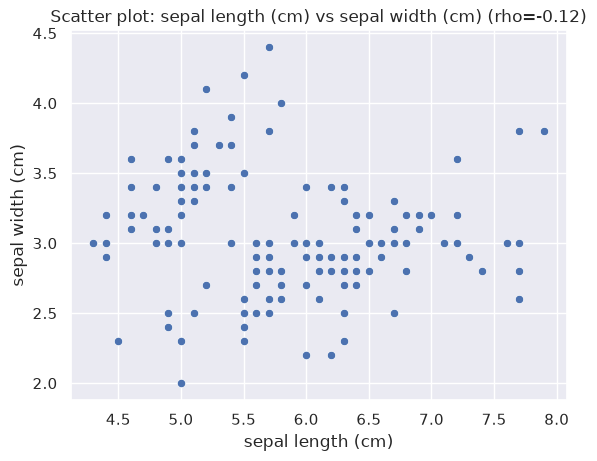

In [20]:
# Plot these two variables
plt.figure()
sns.scatterplot(x=x, y=y)
plt.title(f"Scatter plot: {irisdf.columns[0]} vs {irisdf.columns[1]} (rho={correlation_coefficient:.2f})")
plt.show()

In [21]:
# Now compare sepal length vs petal length (expected higher correlation based on the observed pair plot)
x = irisdf.iloc[:, 0] # Sepal length
y = irisdf.iloc[:, 2] # Petal length

correlation_coefficient, p_value = st.pearsonr(x, y)
print(f"\nCorrelation between '{irisdf.columns[0]}' and '{irisdf.columns[2]}':")
print(f"  Pearson rho = {correlation_coefficient:.4f}")
print(f"  p-value = {p_value:.4e}") # Expect very low p-value


Correlation between 'sepal length (cm)' and 'petal length (cm)':
  Pearson rho = 0.8718
  p-value = 1.0387e-47


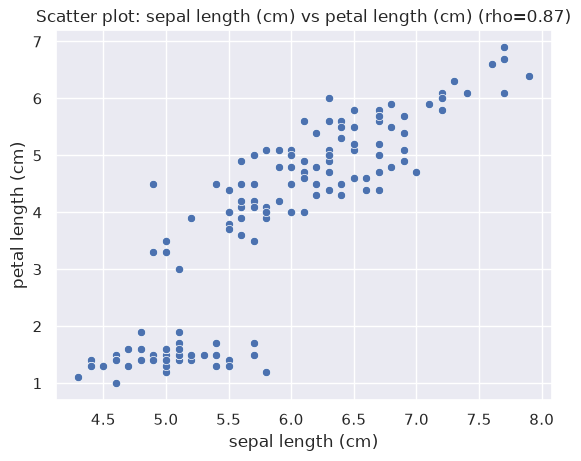

In [22]:
plt.figure()
sns.scatterplot(x=x, y=y)
plt.title(f"Scatter plot: {irisdf.columns[0]} vs {irisdf.columns[2]} (rho={correlation_coefficient:.2f})")
plt.show()

We can compute the correlation matrix via pandas

In [71]:
irisdf.iloc[:,:-1].corr()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
sepal length (cm),1.000000,-0.117570,0.871754,0.817941
sepal width (cm),-0.117570,1.000000,-0.428440,-0.366126
petal length (cm),0.871754,-0.428440,1.000000,0.962865
petal width (cm),0.817941,-0.366126,0.962865,1.000000


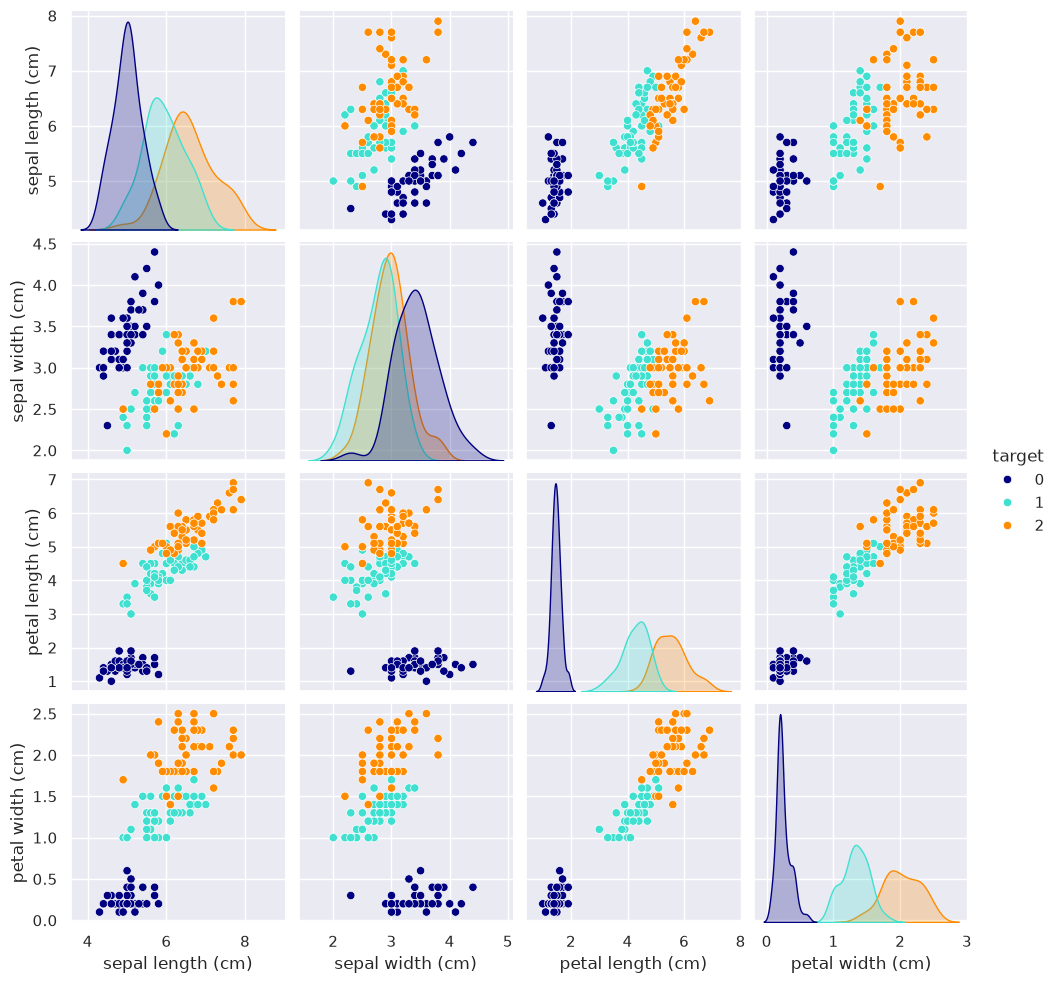

In [72]:
sns.pairplot(irisdf, vars=irisdf.columns[:-1], hue='target', palette={0: 'navy', 1: 'turquoise', 2: 'darkorange'});

Note that, for data which has already been transformed using z-scores, cov and corr are equivalent (although we need to correct for sample vs population statistics)

In [25]:
irisdf_z_scores.iloc[:,:-1].corr()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
sepal length (cm),1.000000,-0.117570,0.871754,0.817941
sepal width (cm),-0.117570,1.000000,-0.428440,-0.366126
petal length (cm),0.871754,-0.428440,1.000000,0.962865
petal width (cm),0.817941,-0.366126,0.962865,1.000000


In [26]:
irisdf_z_scores.iloc[:,:-1].cov() * 149/150

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
sepal length (cm),1.000000,-0.117570,0.871754,0.817941
sepal width (cm),-0.117570,1.000000,-0.428440,-0.366126
petal length (cm),0.871754,-0.428440,1.000000,0.962865
petal width (cm),0.817941,-0.366126,0.962865,1.000000


## Applying Principal Component Analysis (PCA) to the Iris Dataset

There is an extensive demonstration of PCA, and its link to SVD and data projection into reduced dimensions (4 to 2), in the homework. I suggest you take a look at this now, or when it's utilised in following modules.

### To mentimeter

# Probability and Uncertainty

We've looked at describing data with statistics. Now, let's look at **probability**, which is the tool we use to handle [**uncertainty**](https://en.wikipedia.org/wiki/Uncertainty) mathematically. 

We often think about probability in two main ways:

1.   [**Frequentist view:**](https://en.wikipedia.org/wiki/Frequentist_probability) Probability is about how often an event happens if we repeat an experiment many, many times (like the proportion of heads in countless coin flips).

2.  [**Bayesian view:**](https://en.wikipedia.org/wiki/Bayesian_probability) Probability represents our degree of belief that an event will happen, which can be updated as we get more evidence.

**Why Uncertainty Matters:**

Uncertainty is everywhere in science and data analysis. As we discussed in the introduction, it can stem from the inherent randomness in a system (**aleatoric uncertainty**, like rolling a die) or from our lack of knowledge about the system (**epistemic uncertainty**, like errors in a weather forecast model).

Probability theory gives us a means to represent, reason about, and make decisions despite this uncertainty. This is fundamental for building realistic computational models and trustworthy machine learning systems.

Some interesting further reading about the distinctions between the Frequentist and Bayesian way of thinking, and the famous/interesting "Monty Hall" thought experiment:

<https://towardsdatascience.com/statistics-are-you-bayesian-or-frequentist-4943f953f21b>

<https://stats.stackexchange.com/questions/22/bayesian-and-frequentist-reasoning-in-plain-english>

<https://en.wikipedia.org/wiki/Monty_Hall_problem>

<https://towardsdatascience.com/the-monty-hall-problem-388f71a73e1>

<https://www.statisticshowto.com/probability-and-statistics/monty-hall-problem/>

<https://math.stackexchange.com/questions/2862752/how-to-solve-the-monty-hall-problem-using-bayes-theorem>

## Random variables

In probability, we often talk about [**random variables**](https://en.wikipedia.org/wiki/Random_variable).
Unlike the *variables* we use elsewhere, e.g. in standard calculus or linear algebra, a random variable is actually a **function** that maps the [**outcome(s)**](https://en.wikipedia.org/wiki/Outcome_(probability)) of a random experiment to a numerical value.  These values are sometimes termed *states* and the set of all of these states is termed the *target space*.

Think about flipping a coin. The possible **outcomes** are "Heads" (H) and "Tails" (T). We could define a random variable, let's call it $X$, that does this mapping:
* If the outcome is H, then $X = 0$.
* If the outcome is T, then $X = 1$.

Before we flip the coin, we don't know if the outcome will be H or T, so we don't know if $X$ will be 0 or 1. That's why it's called a *random* variable – its value depends on the outcome of a random process.

**Another example:** Roll a standard six-sided die. The outcomes are {1, 2, 3, 4, 5, 6}. We could define a random variable $Y$ that is simply the number shown on the die. So, if the outcome is 4, then $Y=4$.

**Yet another example:** Roll *two* dice. The outcomes are pairs like (1,1), (1,2), ..., (6,6) - there are 36 possible outcomes. We could define a random variable $Z$ to be the *sum* of the numbers on the two dice. If the outcome is (2, 5), then $Z = 2+5 = 7$.

We usually use capital letters like $X, Y, Z$ for random variables.

We can see an immediate example of such a *function* as we can readily execute Python code here:

In [27]:
# Execute this cell several times
print(np.random.rand())

0.7215270747535809


[Actually as this relies on an algorithm implemented in code, this function would be called a [*pseudo* random number](https://en.wikipedia.org/wiki/Pseudorandom_number_generator) generator - see also <https://engineering.mit.edu/engage/ask-an-engineer/can-a-computer-generate-a-truly-random-number/>]

### More definitions (for reference)

Here are a few more terms used in probability. You don't need to memorise them all right now, but they are useful for reference:

* **Random Experiment:** A process with an uncertain outcome (e.g., flipping a coin, rolling a die).

* **Outcome:** A single possible result of a random experiment (e.g., getting 'Heads', rolling a '4').

* **Sample Space (S):** The set of *all possible* outcomes for an experiment. For a single die roll, $S = \{1, 2, 3, 4, 5, 6\}$. For two coin flips, $S = \{HH, HT, TH, TT\}$. (These are examples associated with a discrete random variable, we will also see continuous random variables where the sample space is (uncountably) infinite, i.e. there are infinitely many possible outcomes.)

* **Event:** A *subset* of the sample space – essentially, a collection of one or more outcomes. It often corresponds to a question we ask about the outcome. For a die roll, examples of events are:
    * Rolling a 6: The subset is $\{6\}$.
    * Rolling an odd number: The subset is $\{1, 3, 5\}$.
    * Rolling a number greater than 4: The subset is $\{5, 6\}$.

(Note: An individual single outcome like rolling a '6' is also considered an event, sometimes called an [*elementary event*](https://en.wikipedia.org/wiki/Elementary_event)).

We assign probabilities to *events* (which as just stated includes the individual outcomes).

* [**Stochastic Process:**](https://en.wikipedia.org/wiki/Stochastic_process) A sequence or collection of random variables, often evolving over time. Think of the path taken in a random walk, or the daily fluctuations of a stock price.

**Aside: random walk example**

Here's a code example of a [random walk](https://en.wikipedia.org/wiki/Random_walk) in 2D

based on <https://www.codingem.com/random-walk-in-python/>

In [28]:
# run this cell several times - each time we start from (0,0)
# ... where do we end up and what route do we take?

import random

def randomwalk2D(n):
    # Start at origin
    x = np.zeros(n)
    y = np.zeros(n)

    directions = ["UP", "DOWN", "LEFT", "RIGHT"]
    for i in range(1, n):
        # Pick a random direction for this step
        step = random.choice(directions)

        # Update position based on the previous step
        if step == "RIGHT":
            x[i] = x[i - 1] + 1
            y[i] = y[i - 1]
        elif step == "LEFT":
            x[i] = x[i - 1] - 1
            y[i] = y[i - 1]
        elif step == "UP":
            x[i] = x[i - 1]
            y[i] = y[i - 1] + 1
        elif step == "DOWN":
            x[i] = x[i - 1]
            y[i] = y[i - 1] - 1

    return x, y

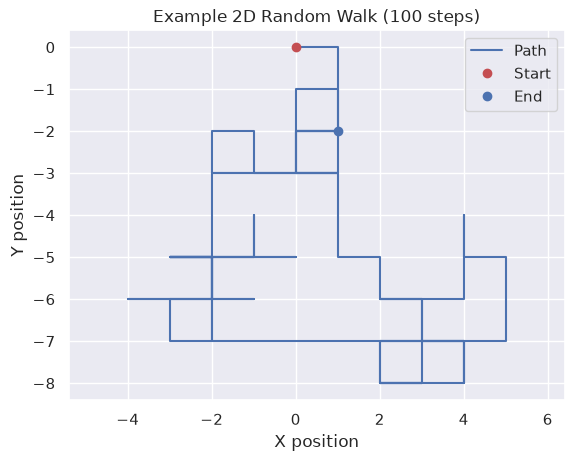

In [29]:
# Generate and plot a walk of 100 steps
n_steps = 100
x_data, y_data = randomwalk2D(n_steps)

plt.figure() # Ensure a new figure
plt.title(f"Example 2D Random Walk ({n_steps} steps)")
plt.plot(x_data, y_data, label='Path') # Plot the path
plt.plot(0, 0, 'ro', label='Start') # Add red circle marker for start
plt.plot(x_data[-1], y_data[-1], 'bo', label='End') # Add blue circle marker for end
plt.xlabel("X position")
plt.ylabel("Y position")
plt.grid(True)
plt.axis('equal') # Make steps look visually square
plt.legend() # Add legend to show start/end markers
plt.show()

### Discrete and continuous random variables

Random variables can be broadly categorised into two types:

1.  **Discrete Random Variable:** The output of the function takes on values from a *finite* or *countably infinite* set. Think of outcomes you can count.
    * Examples: The number rolled on a die (values {1, 2, 3, 4, 5, 6}), the number of heads in 10 coin flips (values {0, 1, ..., 10}), the number of emails arriving in an hour (values {0, 1, 2, ...}).

2.  **Continuous Random Variable:** Takes on any value within a given *range* (an interval). Think of outcomes you measure.
    * Examples: The height of a person, the temperature of a room, the time it takes for a component to fail. These can theoretically take on infinitely many values within a range (e.g., height could be 1.75m, 1.751m, 1.7512m...).

*(In practice, measurements are always made with finite precision, so measured quantities might look discrete. However, it's often mathematically convenient and accurate to model the underlying variable as continuous.)*

## Probability

As above, probability provides a means to measure how likely an event (a specific outcome or set of outcomes from a random experiment) is to happen. Think of it as assigning a number between 0 and 1 to each possible event.

### Properties

Probabilities must satisfy some basic rules:

1.  **Non-negative:** The probability of any event must be greater than or equal to zero. You can't have a negative chance of something happening.

2.  **Maximum of 1:** The probability of any event cannot be more than 1. An event can't be *more* than certain.

3.  **Total Probability:** The sum of the probabilities of all possible *elementary* outcomes (the individual, simplest results) in the sample space must equal 1. Something *must* happen. For a die roll, $P(1) + P(2) + P(3) + P(4) + P(5) + P(6) = 1$.

*(A probability of 1 generally means the event is certain to happen, and 0 means it's impossible. However, see the note below about continuous variables.)*

4.  **Addition Rule (for mutually exclusive events):** If two events cannot happen at the same time (like rolling a 1 and rolling a 2 on a single throw), the probability that *either* one event *or* the other occurs is the sum of their individual probabilities. For example, $P(\text{rolling a 1 or a 3}) = P(1) + P(3)$.

*(You might find this Probability rules cheat sheet (Basic probability rules with examples) useful: <https://medium.com/data-comet/probability-rules-cheat-sheet-e24b92a9017f>)*

<div class="optional">

##### Aside: A note on continuous variables and probability 0 or 1; "almost ..." [\*]

When dealing with *continuous* random variables (like height or temperature), the sample space is infinite. In this case, the probability of getting *exactly* one specific value (e.g. height = 1.75000... meters exactly) is actually zero! 

So, for continuous variables:

    
* A probability of 1 means the event is "**almost surely**" certain (it could technically fail on a set of outcomes with zero total probability).
    
    
* A probability of 0 means the event is "**almost surely**" impossible.

    
Think of randomly picking a single point on a line segment – the chance of picking *exactly* the midpoint is zero, even though the midpoint exists. We usually talk about the probability of the value falling within a *range* for continuous variables.

<br>
    
*For more on this see <https://en.wikipedia.org/wiki/Almost_surely>. This is the analogue of [*almost everywhere*](https://en.wikipedia.org/wiki/Almost_everywhere) in measure theory.

For a fun example take a look at the "Infinite_monkey_theorem": <https://en.wikipedia.org/wiki/Infinite_monkey_theorem>
>a monkey hitting keys at random on a keyboard for an infinite amount of time will "almost surely" type any given text, including the complete works of William Shakespeare.*

</div>

### Notation

Now let's clarify the notation we use:

* We use uppercase letters (e.g., $X$) for **random variables**.
* We use lowercase letters (e.g., $x$) for specific **values** that the random variable can take.
* The probability distribution associated with the random variable $X$ is denoted as $P(X)$ (see next).
* $P(X=x)$ means "the probability that the random variable $X$ takes the specific value $x$".
* We often shorten $P(X=x)$ to just $P(x)$ when the random variable $X$ is clear from the context.

**Examples** (whiteboard)

**Example (Die Roll):** Let $X$ be the random variable representing the outcome of rolling a fair six-sided die.
* The sample space is $S = \{1, 2, 3, 4, 5, 6\}$.
* $P(X=1)$ is the probability of rolling a 1.
* For a *fair* die, $P(X=1) = P(1) = 1/6$. Similarly, $P(2) = 1/6$, ..., $P(6) = 1/6$.
* $P(X=7) = P(7) = 0$, since 7 is not in the sample space.

**Example (Coin Flip):** Let $Y$ be the random variable mapping Heads (H) to 0 and Tails (T) to 1.
* The sample space of outcomes is $\{H, T\}$.
* The possible values for $Y$ are $\{0, 1\}$.
* For a fair coin, $P(Y=0) = P(0) = 1/2$ (the probability of getting Heads).
* $P(Y=1) = P(1) = 1/2$ (the probability of getting Tails).

## Probability Distribution Function

We use a [**probability distribution function**](https://en.wikipedia.org/wiki/Probability_distribution) to describe the probabilities for *all* possible outcomes of a random variable. 

This function assigns a probability (or something related to probability, as we'll see) to each possible value the random variable can take.

There are two main types, depending on whether the random variable is discrete or continuous:

1.  [**Probability Mass Function (PMF):**](https://en.wikipedia.org/wiki/Probability_mass_function) For **discrete** random variables.
2.  [**Probability Density Function (PDF):**](https://en.wikipedia.org/wiki/Probability_density_function) For **continuous** random variables.

Note that for discrete random variables we can obtain the probability of an event from the probability of individual outcomes, e.g. the probability of an even dice throw = sum of probabilities of rolling 2, 4 or 6. Hence it is sufficient for us to just define a function that assigns probabilities to outcomes.

However, for a continuous random variable the probability of any individual outcome is actually zero and so we might think instead of an interval of outcomes, i.e. a subset of the sample space = an event.

### Probability Mass Functions

For a **discrete** random variable $X$, the [**probability mass functions** (or PMFs)](https://en.wikipedia.org/wiki/Probability_mass_function) gives the probability that $X$ is exactly equal to some specific value $x$. Remember our notation: we write this as $P(X=x)$ or just $P(x)$.

**Example: Fair Die Roll**
Let $X$ be the outcome of rolling a fair six-sided die. The sample space is $S=\{1, 2, 3, 4, 5, 6\}$.  Assuming that the die is fair, each outcome is *equiprobable*: if we run the experiment a large number of times, we will get each outcome approximately the same number of times. Here, assuming a six-sided die, there are six possible outcomes, so we have a  one over six chance of rolling each number.

Thus, the probability mass function describing $X$ returns $\frac{1}{6}$ for each possible outcome, and technically 0 otherwise since we cannot get something different than 1, 2, 3, 4, 5, or 6. 

The PMF for this experiment is:
$$P(X=x) \equiv P(x) = \begin{cases} 1/6 & \text{if } x \in \{1, 2, 3, 4, 5, 6\} \\ 0 & \text{otherwise} \end{cases}$$
This function tells us the probability 'mass' concentrated at each specific possible outcome.

**Aside:**

Also common is the notation ("p sub x"):

$$p_X(x) = P(X=x)$$

where $p_X(x)$ is a function from $\mathbb{R}$ (the set of all real numbers) into the interval $[0,1]$, i.e. $p_X:\mathbb{R}\rightarrow [0,1]$.

We will plot such a function shortly.

### Properties of Probability Mass Functions

A function $P(x)$ can only be a valid PMF if it meets two conditions:

1.  **Probabilities between 0 and 1:** For any value $x$, $0 \leq P(x) \leq 1$

2.  **Total Probability is 1:** The sum of the probabilities over all possible outcomes in the sample space $S$ must equal 1:
    $$\sum_{x \in S} P(x) = 1$$
    (Since $P(x)=0$ for any $x$ not in $S$, we could also legitimately write the sum over all real numbers: $\sum_{x \in \mathbb{R}} P(x) = 1$).

### Simulation of a die-rolling experiment

Let's simulate a die-rolling random experiment using the NumPy function `np.random.randint(low, high, size)`, which draws $n$ (`size`) random integers between `low` and `high` (high excluded) from a [*discrete uniform distribution*](https://en.wikipedia.org/wiki/Discrete_uniform_distribution) (i.e. each value equally likely to occur). 

We begin by simulating 20 die rolls, and printing the 20 outcomes we obtain:

In [30]:
# Run this cell several times, with and without setting a random seed


# Function to simulate n die rolls
def dice_experiment(n):
    # Set the seed if you want to make the random experiment reproducible.
    # If you exclude this you should get a different result each time you run.
    #np.random.seed(1)
    # Rolls are integers from 1 (inclusive) up to 7 (exclusive) ...
    # return n rolls from the S = {1, 2, 3, 4, 5, 6} sample space
    return np.random.randint(low=1, high=7, size=n)

n_rolls = 20
outcomes_20 = dice_experiment(n_rolls)
print(f"Outcomes of {n_rolls} rolls:\n{outcomes_20}")

Outcomes of 20 rolls:
[5 5 6 3 3 6 2 4 2 3 5 4 6 1 2 3 4 3 1 5]


This array contains 20 outcomes of the random experiment. 

Define $X$ to be the discrete random variable corresponding to the die rolling experiment. The probability mass function of $X$ is defined only for the possible outcomes and gives us the probability for each of them.

Let's visualise how many times each outcome occurred in the random experiment. 

By dividing the number of occurrences of each outcome (which we obtain using [`numpy.unique`](https://numpy.org/doc/stable/reference/generated/numpy.unique.html) with the "return_counts" option) by the total number of rolls $n$ we get the probabilities. This gives us our *empirical* PMF based on these 20 rolls.
 Assuming the die is fair, we *expect* to obtain a *uniform distribution* - i.e. we expect each of the six outcomes to have the probability 1/6.

We will use a stem plot [`plt.stem()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.stem.html) from Matplotlib to visualise these probabilities:

In [31]:
# Function to calculate empirical probabilities from outcomes
def calculate_probabilities(outcomes):
    # Find unique outcomes and how many times each occurred
    values, counts = np.unique(outcomes, return_counts=True)
    total_outcomes = len(outcomes)
    probabilities = counts / total_outcomes
    # Ensure all outcomes 1-6 are represented, even if they had 0 count
    prob_dict = dict(zip(values, probabilities))
    full_values = np.arange(1, 7)
    full_probabilities = np.array([prob_dict.get(i, 0) for i in full_values])
    return full_values, full_probabilities

In [32]:
# Function to plot the PMF using a stem plot
def plot_pmf(values, probabilities, title="Probability Mass Function"):
    plt.figure()
    # Use stem plot for discrete distributions
    plt.stem(values, probabilities, basefmt=" ")
    plt.xlabel("Outcome (x)")
    plt.ylabel("Probability P(x)")
    plt.title(title)
    # Set y-limit to make comparisons easier, e.g., slightly above 1/6
    plt.ylim(0, 0.3)
    # Ensure x-axis ticks show all integer outcomes
    plt.xticks(np.arange(1, 7))
    plt.grid(True, axis='y')
    plt.show()


Empirical probabilities from 20 rolls:
 P(1) = 0.1500
 P(2) = 0.1500
 P(3) = 0.1000
 P(4) = 0.1500
 P(5) = 0.2500
 P(6) = 0.2000


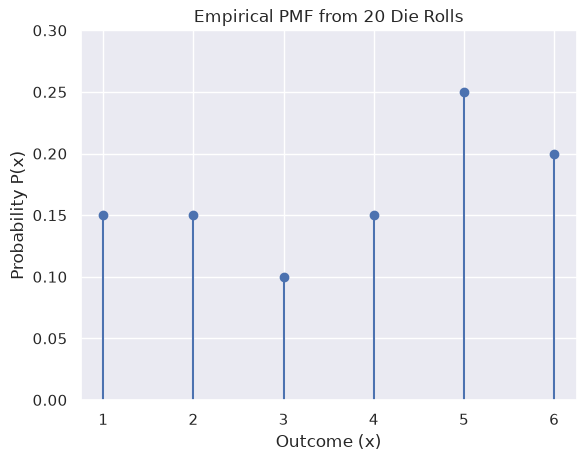


Sum of probabilities: 1.0000


In [75]:
# Calculate and plot for 20 rolls

n_rolls = 20
outcomes_20 = dice_experiment(n_rolls)

values_20, probs_20 = calculate_probabilities(outcomes_20)
print(f"\nEmpirical probabilities from {n_rolls} rolls:")
for v, p in zip(values_20, probs_20):
    print(f" P({v}) = {p:.4f}")

plot_pmf(values_20, probs_20, title=f"Empirical PMF from {n_rolls} Die Rolls")

# Check that the probabilities sum to 1
print(f"\nSum of probabilities: {np.sum(probs_20):.4f}")

With only 20 rolls, the plot doesn't look very uniform (flat). This is due to random chance in a small sample.

Now, let's repeat the experiment but with a much larger number of rolls, say 1 million. According to the **Law of Large Numbers**, the empirical probabilities should converge towards the true theoretical probabilities ($1/6$).


Empirical probabilities from 1000000 rolls:
 P(1) = 0.166453 (Theoretical = 0.166667)
 P(2) = 0.166533 (Theoretical = 0.166667)
 P(3) = 0.166163 (Theoretical = 0.166667)
 P(4) = 0.167179 (Theoretical = 0.166667)
 P(5) = 0.166729 (Theoretical = 0.166667)
 P(6) = 0.166943 (Theoretical = 0.166667)


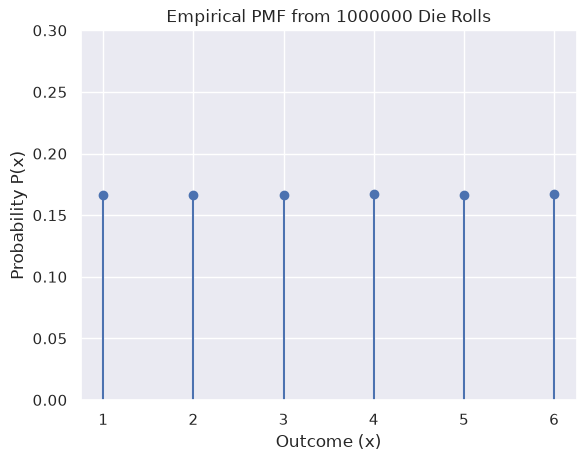


Sum of probabilities: 1.0000


In [34]:
# Simulate 1 million rolls
n_rolls_large = 1_000_000
outcomes_large = dice_experiment(n_rolls_large)

# Calculate and plot for the large number of rolls
values_large, probs_large = calculate_probabilities(outcomes_large)
print(f"\nEmpirical probabilities from {n_rolls_large} rolls:")
for v, p in zip(values_large, probs_large):
    print(f" P({v}) = {p:.6f} (Theoretical = {1/6:.6f})")

plot_pmf(values_large, probs_large, title=f"Empirical PMF from {n_rolls_large} Die Rolls")

# Check that the probabilities sum to 1
print(f"\nSum of probabilities: {np.sum(probs_large):.4f}")

As expected, with 1 million rolls, the empirical PMF is much closer to the uniform distribution where each outcome has a probability near $1/6$.

[more on this in the homework]

### Probability Density Functions

With continuous variables, there are an infinite number of possible outcomes. 

For instance, say we were drawing a number between 0 and 1 - you might get an outcome of, for example, 0.413949834...

**Question**: What is the probability of getting one particular outcome with a continuous variable?

**Answer**: Zero!

And that's the case whether or not we can write the outcome down in finite digits or not (i.e. for pi as well as for 1.0):
The probability of a continuous random variable $X$ taking any *single exact* value $x$ is zero ($P(X=x) = 0$). This is because there are infinitely many possible values in any given range.

So, instead of talking about the probability of a specific value, we talk about the probability of the outcome falling *within a certain interval* or a range of values. The $y$-axis of a probability function in the case of continuous random variables is therefore NOT actually a probability. 

### Probability density functions: key properties <a class="tocSkip"></a>

For continuous variables, we use a  [**probability density functions**](https://en.wikipedia.org/wiki/Probability_density_function) or PDF, usually written as $p(x)$. The key things to remember about a PDF are:

1.  **Density, not Probability:** The value $p(x)$ itself is **not** a probability (the $y$-axis in our plots). It's a **probability density**. Densities can be greater than 1 (unlike probabilities).

2.  **Area under the curve = Probability:** The probability that $X$ falls within an interval $[a, b]$ is given by the **area under the PDF curve** between $a$ and $b$. Mathematically, this is the definite integral (cf. quadrature in lecture 5):
    $$P(a \leq X \leq b) = \int_{a}^{b} p(x) \, dx$$

(So note that the probability of a single value for $x$, i.e. single outcome, can be interpreted as the integral over a zero width interval (area under curve $\approx$ zero width multiplied by a *finite* height), which would be zero.)

3.  **Total Area = 1:** The total area under the entire PDF curve must equal 1. This corresponds to the fact that the random variable must take *some* value:
    $$\int_{-\infty}^{\infty} p(x) \, dx = 1$$

4.  **Non-negative:** The density function must always be non-negative: $p(x) \geq 0$ for all $x$.

*(Think of density like mass density. A point doesn't have mass, but a region has mass found by integrating the density over that region. Similarly, a single value has zero probability, but an interval has probability found by integrating the probability density.)*

##### Aside

Contrast this with the Dirac-delta function (its "height" and the properties of its integral).

### Example 1: The Normal (Gaussian) Distribution

A very common continuous distribution is the [*Normal distribution*](https://en.wikipedia.org/wiki/Normal_distribution) , also called the **Gaussian distribution**. Its PDF has the famous "bell curve" shape. 

The formula for the normal PDF is:

$$p(x; \mu, \sigma) = \frac{1}{\sigma\sqrt{2\pi}} e^{-\frac{1}{2}\left(\frac{x - \mu}{\sigma}\right)^2}$$

Here, $\mu$ is the **mean** (centre of the peak) and $\sigma$ is the **standard deviation** (which controls the spread or width of the bell). $\sigma^2$ is the variance.

Let's simulate drawing random numbers from a Normal distribution using `numpy.random.normal(loc=mean, scale=std_dev, size=n)` and visualise the result using a histogram. A histogram approximates the PDF by counting how many samples fall into different bins (intervals).

In [76]:
# Parameters for the normal distribution
mean_val = 0
std_dev_val = 0.1
n_samples = 10_000

# Draw samples from the normal distribution
np.random.seed(1) # fixed seed for reproducible results (comment out for new samples each run)
samples = np.random.normal(loc=mean_val, scale=std_dev_val, size=n_samples)

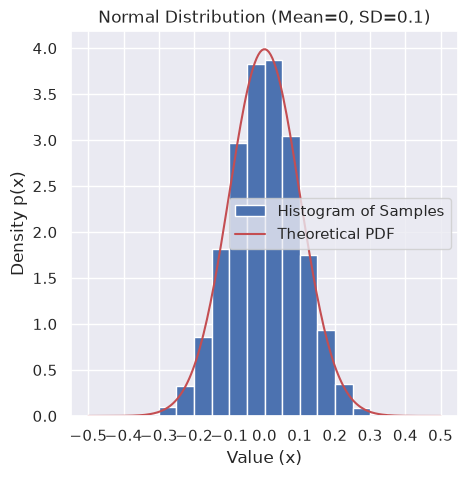

In [77]:
# Plot a histogram of the samples
fig = plt.figure(figsize=(5, 5))
ax1 = fig.add_subplot(111)
# Use density=True to normalise the histogram so the area sums to 1 (approximating a PDF)
ax1.hist(samples, bins=20, range=(-0.5, 0.5), density=True, label='Histogram of Samples')
# Set the ticks step size
ax1.xaxis.set_major_locator(ticker.MultipleLocator(0.1))

# Plot the theoretical PDF on top
x_values = np.linspace(-0.5, 0.5, 200)
# Create a normal distribution object from scipy.stats
normal_dist = st.norm(loc=mean_val, scale=std_dev_val)
pdf_values = normal_dist.pdf(x_values)
ax1.plot(x_values, pdf_values, 'r-', label='Theoretical PDF')

ax1.set_xlabel("Value (x)")
ax1.set_ylabel("Density p(x)")
ax1.set_title(f"Normal Distribution (Mean={mean_val}, SD={std_dev_val})")
ax1.legend()
ax1.grid(True)

Note the classic "bell curve" *trying* to emerge in the histogram representing the sample data. 

The histogram approximates the shape of the theoretical red curve (the PDF). Increasing the number of samples (`n_samples`) or adjusting the number of `bins` in the histogram would typically make the approximation better.

*(The optional homework exercise on the Gaussian integral shows why the normal PDF integrates to 1).*

<div class="optional">

### Kernel density estimation [*] <a class="tocSkip"></a>

We can also use the kdeplot function to plot an approximation to the distribution for this data.

>Kernel density estimation <https://seaborn.pydata.org/tutorial/distributions.html#tutorial-kde>
A histogram aims to approximate the underlying probability density function that generated the data by binning and counting observations. Kernel density estimation (KDE) presents a different solution to the same problem. Rather than using discrete bins, a KDE plot smooths the observations with a Gaussian kernel, producing a continuous density estimate:
    
</div>

<Axes: ylabel='Density'>

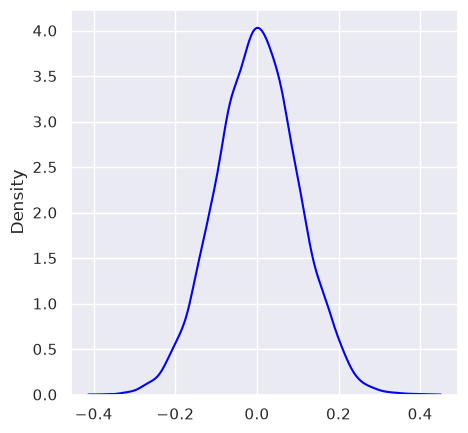

In [37]:
fig = plt.figure(figsize=(5, 5))
ax1 = fig.add_subplot(111)
# use the sns axes level function kdeplot - alternatively you could just try matplotlib hist
sns.kdeplot(samples, ax=ax1, color='blue')

### Cumulative Distribution Function (CDF)

For both discrete and continuous random variables, we can define the [**cumulative distribution function (CDF)**](https://en.wikipedia.org/wiki/Cumulative_distribution_function), usually denoted by $F(x)$. The CDF gives the probability that the random variable $X$ takes a value *less than or equal to* a specific value $x$:

$$F(x) = P(X \leq x)$$

**Properties of CDFs:**
* $F(x)$ is always non-decreasing (it goes up or stays flat as $x$ increases).
* $F(x)$ approaches 0 as $x \to -\infty$.
* $F(x)$ approaches 1 as $x \to +\infty$.
* The value $F(x)$ is always between 0 and 1 (inclusive), because it represents a probability.

**Relationship between PDF and CDF (for continuous variables):**
The CDF is the integral of the PDF from $-\infty$ up to $x$:
$$F(x) = \int_{-\infty}^{x} p(t) \, dt$$
Conversely, the PDF is the derivative of the CDF:

$$p(x) = \frac{dF(x)}{dx}$$

Using the CDF, we can find the probability of $X$ being in an interval $[a, b]$:

$$P(a < X \leq b) = F(b) - F(a)$$

(Note: For continuous variables, $P(a < X \leq b) = P(a \leq X \leq b)$ because $P(X=a)=0$ and $P(X=b)=0$).

Let's plot the CDF for our normal distribution example:

*(Also, see a homework exercise that asks you to compute and plot the CDF yourself.)*

*(Note that as we're now considering an interval, the $y$ axis of a plot of this **does** correspond to a probability.)*

(-0.05, 1.05)

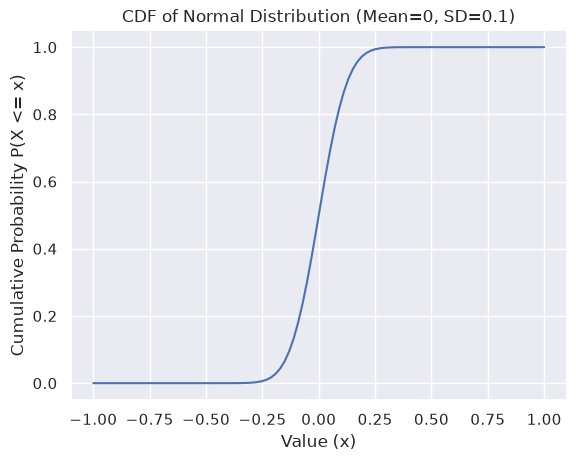

In [38]:
# Parameters from before
mean_val = 0
std_dev_val = 0.1

# Normal distribution object
normal_dist = st.norm(loc=mean_val, scale=std_dev_val)

# Compute CDF values at a sequence of x locations between -1 and 1
x_values_cdf = np.linspace(-1, 1, 100) # Use a suitable range
cdf_values = normal_dist.cdf(x_values_cdf)

# Plot the CDF
plt.figure()
plt.plot(x_values_cdf, cdf_values)
plt.xlabel("Value (x)")
plt.ylabel("Cumulative Probability P(X <= x)")
plt.title(f"CDF of Normal Distribution (Mean={mean_val}, SD={std_dev_val})")
plt.grid(True)
plt.ylim(-0.05, 1.05) # Set y-limits from 0 to 1

The CDF starts near 0 for small $x$, increases, and levels off near 1 for large $x$. The value of the CDF at $x=0$ (the mean) is 0.5, because the normal distribution is symmetric around its mean.

*(A homework exercise asks you to reconstruct the CDF plot using only the PDF and the definition of the CDF as an integral).*

### Example 2: Modelling the Iris Data with a Normal Distribution

Let's return to the Iris dataset. Can we model the distribution of a feature, like 'sepal length (cm)' for one species (say, Iris Setosa, target=0), using a normal distribution?

First, let's isolate the sepal length (first column) data for Iris Setosa (`target=0`)  and plot its histogram.

In [78]:
# DataFrame for Iris setosa
iris_setosa_df = irisdf.loc[irisdf['target'] == 0]
iris_setosa_df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


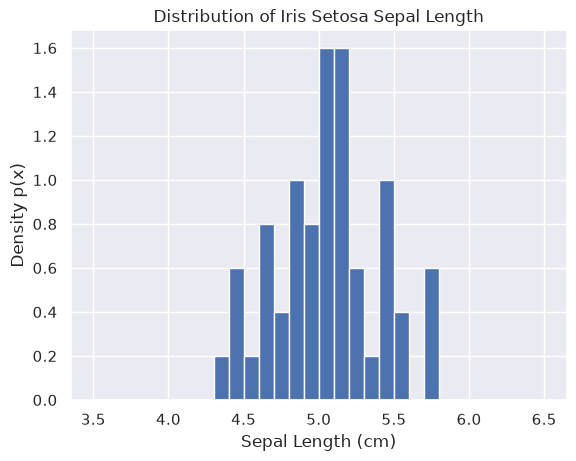

In [79]:
# Extract the sepal length as a numpy array.
sepal_length_setosa = iris_setosa_df['sepal length (cm)'].to_numpy()

plt.figure()
plt.hist(sepal_length_setosa, range=(3.5, 6.5), bins=30, density=True, label='Setosa Sepal Length Histogram') 
plt.xlabel('Sepal Length (cm)')
plt.ylabel('Density p(x)')
plt.title('Distribution of Iris Setosa Sepal Length')
plt.grid(True, axis='y')

The histogram looks roughly bell-shaped, suggesting a normal distribution might be a reasonable, though perhaps not perfect, model - we only have 50 samples to go by.

To fit a normal distribution, we need the mean and standard deviation of this specific data (Setosa sepal length). We can calculate these from our filtered data of course.

In [80]:
# Here are all of the means
irisdf.groupby(['target']).mean()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
target,,,,
0,5.006,3.428,1.462,0.246
1,5.936,2.770,4.260,1.326
2,6.588,2.974,5.552,2.026


In [81]:
# and all of the standard deviations
irisdf.groupby(['target']).std()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
target,,,,
0,0.352490,0.379064,0.173664,0.105386
1,0.516171,0.313798,0.469911,0.197753
2,0.635880,0.322497,0.551895,0.274650


Now that we have computed the mean and the standard deviation, we can use them to *estimate* the normal distribution of these measurements. 

For example, for target $0$ (Iris Setosa), the sepal length has a mean of $5.006 \,\text{cm}$ and standard deviation of $0.352490\,\text{cm}$. 

Here is the plot of the *estimated distribution* that describes sepal length for Iris Setosa, plotted on top of the histogram of the actual data.

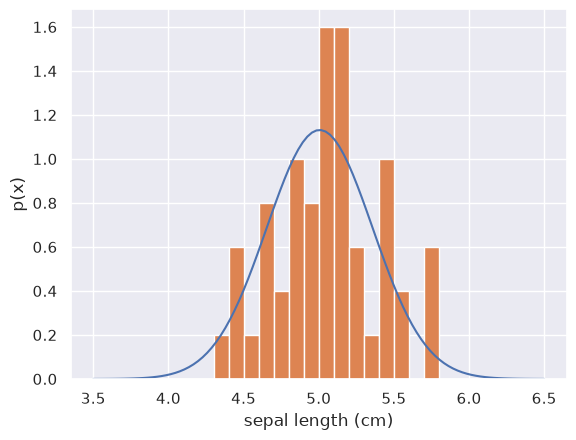

In [82]:
# mean and standard deviation for Setosa sepal length
mean = 5.006  # cm
standard_deviation = 0.352490  # cm

# Define the corresponding normal distribution PDF
normal_distribution = st.norm(mean, standard_deviation)

# Compute PDF values at series of x locations for plotting
x_values = np.linspace(3.5, 6.5, 100)
y_values = normal_distribution.pdf(x_values)

# Plot the normal distribution and the underlying histogram
plt.plot(x_values, y_values)  # normal distribution
plt.hist(sepal_length_setosa, range=(3.5, 6.5), bins=30, density=True)  # iris setosa sepal length

# Label axes
plt.xlabel('sepal length (cm)')
plt.ylabel(r'p(x)')

plt.show()

The blue curve shows the normal distribution using the calculated mean and standard deviation. It seems to capture the general shape of the data's distribution reasonably well.

**Using the Model for Probability Calculation**

Now, let's use our *fitted normal model* to estimate the probability of observing a specific measurement. For instance, what's the probability that an Iris Setosa flower has a sepal length measured and recorded as exactly $5.1\,\text{cm}$?

Remember, for a continuous distribution, $P(X = 5.1) = 0$. However, the measurements in the dataset are given to one decimal place (0.1 cm precision). So, a recorded value of 5.1 cm likely represents a true value somewhere in the interval $(5.1 - 0.05, 5.1 + 0.05)$, i.e., from 5.05 cm up to 5.15 cm.

We can calculate the probability of the sepal length falling in this interval using the CDF of our fitted normal distribution:

$$P(5.1 - 0.05 \lt X\leq 5.1 + 0.05) = F(5.15) - F(5.05)$$

In [83]:
# Since the smallest measurement in the dataset is 0.1 cm,
# we use the range (x-eps) - (x+eps) (with eps=0.05) to calculate the probability.
def calc_probability(x, distribution, eps=0.05):
    # use the cdf = cumulative distribution function
    return distribution.cdf(x+eps) - distribution.cdf(x-eps)

x = 5.1
probability = calc_probability(x, normal_distribution)

print(f'The probability of sepal length being {x} cm for iris setosa is {probability}.')

The probability of sepal length being 5.1 cm for iris setosa is 0.10888540054111928.


This is the integral under the blue curve above, over an interval of width 0.1 where we can observe the height of the curve at location 5.1 is around 1.1 (base $\times$ height $\approx$ 0.1) and so we see that the value we've calculated here looks correct.

This gives us an estimate, based on our normal distribution model, of how likely we are to observe a measurement recorded as 5.1 cm for an Iris Setosa sepal length. The quick check (multiplying the PDF height by the interval width) gives a rough agreement, confirming our calculation is reasonable.

<div class="optional">
    
## Central Limit Theorem [*]

The [**central limit theorem**](https://en.wikipedia.org/wiki/Central_limit_theorem) states that, if we consider $n$ independent random variables drawn from the same distribution (any distribution with finite variance, not necessarily normal) with large enough $n$ and AVERAGE OR SUM their outcomes, the distribution of the results will be approximated by a Gaussian (normal) distribution. 

<br>

Why is this important? From <https://en.wikipedia.org/wiki/Central_limit_theorem>:

    "The theorem is a key concept in probability theory because it implies that probabilistic and statistical methods that work for normal distributions can be applicable to many problems involving other types of distributions." *[provided we are looking at sums or averages of samples.]*
    
    "Since real-world quantities are often the balanced sum of many unobserved random events, the central limit theorem also provides a partial explanation for the prevalence of the normal probability distribution." - explains why the normal distribution appears so often in nature and in data.


<br>

Let's see this in action.

We have seen that the outcome of a single die follows the uniform distribution, i.e. all six outcomes are equally likely. That is, as we approximated above, if we throw one die multiple times our results converge to a uniform distribution as long as we throw the die enough times (1,000,000 rolls in the next cell). 

<br>

But let's also build a function that can simulate throwing a number $n$ (`n_dice`) of dice, and sum (or average) their results, and then perform this experiment `n_trials` (100,000) times. 

<br>

The CLT tells us that the PDF of this sum (or average) should look like a normal rather than uniform distribution, assuming that $n$ (`n_dice`) is large enough
    
</div>

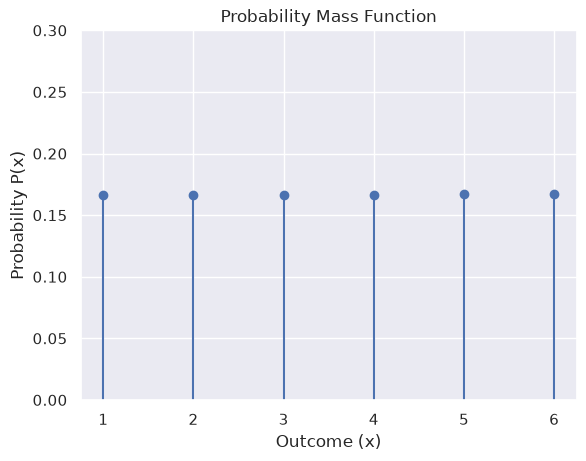

In [45]:
# Roll one die 1M times

def dice_experiment(n):
    # Set the seed if you want to make the random experiment reproducible.
    # If you exclude this you should get a different result each time you run.
    np.random.seed(1)
    # return n rolls from the S = {1, 2, 3, 4, 5, 6} sample space
    return np.random.randint(low=1, high=7, size=n)


n = 1_000_000
outcomes = dice_experiment(n)
plot_pmf(*calculate_probabilities(outcomes))

In [46]:
# now use randint to simulate throwing n_dice at once, sum the result
# and record this sum n_trials times
def sum_distribution_dice(n_dice, n_trials=100_000):
    sums = np.zeros(n_trials)
    for i in range(n_trials):
        # Simulate n_dice rolls and sum them
        sums[i] = np.random.randint(low=1, high=7, size=n_dice).sum()
    return sums

Now, we’ll use this function to evaluate the distribution of the sums for 1, 2, and 30 dice:

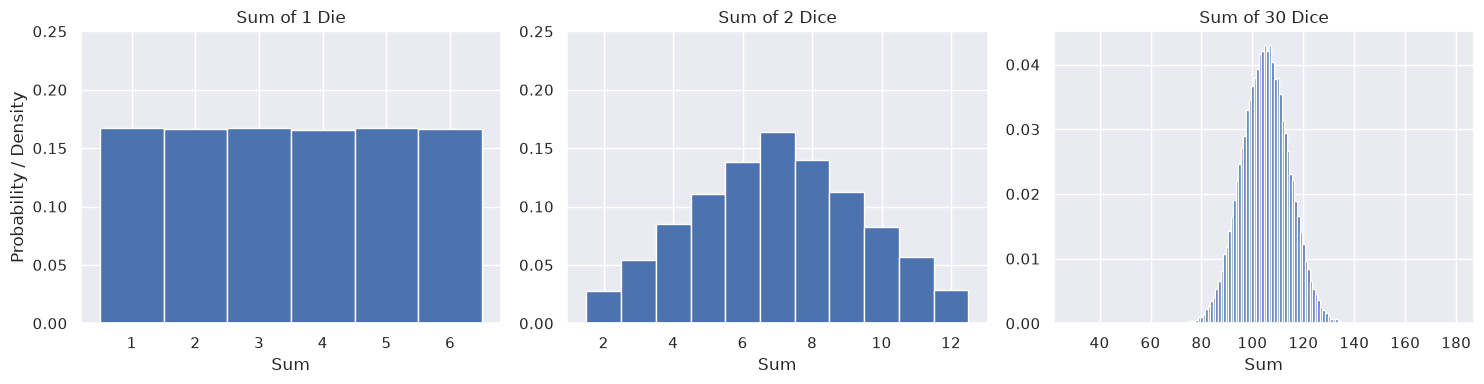

In [47]:
# --- Run simulations for 1, 2, and 30 dice ---
np.random.seed(1) # For reproducibility

sums_dice_1 = sum_distribution_dice(1)
sums_dice_2 = sum_distribution_dice(2)
sums_dice_30 = sum_distribution_dice(30)

# --- Plot the results ---
fig, axes = plt.subplots(1, 3, figsize=(15, 4)) # Adjusted figsize
ax0, ax1, ax2 = axes

# Plot histograms of the sums, using density=True to approximate a PDF/PMF
# Adjust bins based on the possible range of sums
ax0.hist(sums_dice_1, bins=np.arange(1, 8)-0.5, density=True) # Bins centered on 1, 2,.. 6
ax0.set_title('Sum of 1 Die')
ax0.set_xlabel('Sum')
ax0.set_ylabel('Probability / Density')
ax0.set_ylim(0, 0.25)

ax1.hist(sums_dice_2, bins=np.arange(2, 14)-0.5, density=True) # Sums range from 2 to 12
ax1.set_title('Sum of 2 Dice')
ax1.set_xlabel('Sum')
# ax1.set_ylabel('Probability / Density') # Y label shared
ax1.set_ylim(0, 0.25)

ax2.hist(sums_dice_30, bins=np.arange(30, 181)-0.5, density=True) # Sums range from 30 to 180
ax2.set_title('Sum of 30 Dice')
ax2.set_xlabel('Sum')
# ax2.set_ylabel('Probability / Density') # Y label shared
ax2.set_ylim(bottom=0) # Auto-adjust y-limit for the bell curve

plt.tight_layout()
plt.show()

**Observations:**

* **1 Die:** The histogram is flat, representing the uniform distribution of a single die roll.
* **2 Dice:** The histogram is triangular. The sum of 7 is the most likely (combinations: 1+6, 2+5, 3+4, 4+3, 5+2, 6+1), while sums of 2 (1+1) and 12 (6+6) are the least likely. This is clearly not uniform.
* **30 Dice:** The histogram looks very much like a normal distribution (bell curve), centered around the expected average sum (30 dice * 3.5 average per die = 105).

This demonstrates the Central Limit Theorem in action: even though the individual die rolls are uniformly distributed, the distribution of their *sum* becomes approximately normal as we add more dice together.

<br>

Let's check the result above is consistent with our expectation:

In [48]:
# use Counter to add up how many times we obtain each total
from collections import Counter
# https://docs.python.org/3/library/collections.html#collections.Counter
# https://pymotw.com/2/collections/counter.html

res = Counter(sums_dice_2)
print(res,'\n')

for dsum in range(2,13):
    # print out 36 times the probability computed based on the ratio,
    # this should approach 1,2,3,4,5,6,5,4,3,2,1 for large sample sizes
    print(dsum, res[dsum]/len(sums_dice_2), 36*res[dsum]/len(sums_dice_2))

Counter({np.float64(7.0): 16399, np.float64(8.0): 13956, np.float64(6.0): 13853, np.float64(9.0): 11216, np.float64(5.0): 11070, np.float64(4.0): 8474, np.float64(10.0): 8270, np.float64(11.0): 5704, np.float64(3.0): 5439, np.float64(12.0): 2833, np.float64(2.0): 2786}) 

2 0.02786 1.00296
3 0.05439 1.95804
4 0.08474 3.05064
5 0.1107 3.9852
6 0.13853 4.98708
7 0.16399 5.90364
8 0.13956 5.02416
9 0.11216 4.03776
10 0.0827 2.9772
11 0.05704 2.05344
12 0.02833 1.01988


And indeed the third column does start to approximate what we expect: 1,2,3,4,5,6,5,4,3,2,1.

For further examples see 

- <https://en.wikipedia.org/wiki/Illustration_of_the_central_limit_theorem>

- <https://medium.com/analytics-vidhya/central-limit-theorem-and-machine-learning-part-1-af3b65dc9d32>

- <https://web.archive.org/web/20211125055504/https://towardsdatascience.com/central-limit-theorem-in-action-1d4832599b7f> (archived copy)

- <https://machinelearningmastery.com/a-gentle-introduction-to-the-central-limit-theorem-for-machine-learning/>

    From the latter: "The Central Limit Theorem, or CLT for short, is an important finding and pillar in the fields of statistics and probability. ... It may seem a little esoteric at first, so hang in there. It turns out that the finding is critically important for making inferences in applied machine learning."

## Joint and Conditional Probabilities (brief overview - see supp material)

Often, we're interested in the probability of multiple events happening or how the probability of one event changes when we know another has occurred. This leads to the ideas of **joint** and **conditional** probability.

*(For more detailed explanations, derivations, and several examples see the supplementary notebook.)*

### Joint Probability

The [**joint probability**](https://en.wikipedia.org/wiki/Joint_probability_distribution) is the probability that *two or more* events happen together. If we have two random variables $X$ and $Y$, the joint probability that $X$ takes the value $x$ *and* $Y$ takes the value $y$ is written as:

$$P(X=x, Y=y)$$

**Independent Events:**
If two events $X=x$ and $Y=y$ are **independent** (meaning the outcome of one doesn't affect the outcome of the other, like rolling two separate dice), their joint probability is simply the product of their individual probabilities:

$$P(X=x, Y=y) = P(X=x) P(Y=y) \quad \text{(if independent).}$$

**Dependent Events:**
If events are **dependent** (the outcome of one affects the other, like drawing cards from a pack without replacement), we need conditional probability to calculate their joint probability (see Product Rule below).

### Marginal Probability (Sum Rule)

If we have the joint probability $P(X=x, Y=y)$ for all possible pairs of $x$ and $y$, we can find the probability of just one event, say $P(X=x)$, regardless of what $Y$ does. 

This involves eliminating the variables you're not interested in by considering all their possible values
and is called the **marginal probability**. 

We get it by summing (or integrating for continuous variables) the joint probabilities over all possible values of the other variable(s) - "we marginalise the other variables". This is known as the **sum rule**:

$$P(X=x) = \sum_{y} P(X=x, Y=y)$$

*(The $\sum$ becomes an $\int$ for continuous variables)*.

### Conditional Probability

**Conditional probability** is the probability of an event happening *given that* another event has already happened. 
We write the probability of $Y=y$ ***given*** $X=x$ as:

$$P(Y=y \,|\, X=x)$$

This reads as "the probability of Y equals y, given that X equals x".  The comma vs the "|" between $x$ and $y$ is important!

### The Product Rule (Connecting Joint and Conditional)

The **product rule** (also called the chain rule) connects joint and conditional probability. 

It states that the joint probability of two events is the probability of one event *times* the conditional probability of the second event given the first:

$$P(X=x, Y=y) = P(Y=y \,|\, X=x) P(X=x)$$

Assuming $P(X=x) \neq 0$, we can rearrange this to define conditional probability in terms of joint and marginal probabilities:

$$P(Y=y \,|\, X=x) = \frac{P(X=x, Y=y)}{P(X=x)}$$

These rules are fundamental for understanding how different events or variables relate to each other, and they form the basis for important concepts like Bayes' Theorem, which we'll see below.

### To mentimeter

# Machine Learning, Data Science - "simple" methods and links to probability

We've covered the basics of statistics for describing data and probability for handling uncertainty. Now, let's see how these ideas form the foundation for **Machine Learning (ML)** and **Data Science**.

Essentially, ML algorithms learn patterns from data. Instead of explicitly programming rules, we provide data and let the algorithm figure out the relationships. Probability plays a key role here, both in how the algorithms learn (e.g. estimating the likelihood of patterns) and in how we interpret their outputs (e.g. the probability of a certain classification being correct).

Your next two modules dive deep into Data Science & ML and Deep Learning in detail, so here we'll just introduce some basic concepts and show how they connect directly to the probability theory we've just discussed, and also link back to regression from Lecture 5.

**What is Machine Learning?**

A commonly cited definition comes from Tom Mitchell (1997):

> "*A computer program is said to learn from experience E with respect to some task T and some performance measure P if its performance on T, as measured by P, improves with experience E.*"

* **Task (T):** What we want the program to do (e.g. classify emails as spam/not spam, predict house prices).
* **Experience (E):** The data the program uses to learn (e.g. a dataset of labelled emails, past house sale records).
* **Performance (P):** How we measure how well the program is doing the task (e.g. percentage of emails classified correctly, average error in price predictions).

Further background reading:

- <https://web.archive.org/web/20221004093958/https://towardsdatascience.com/what-is-machine-learning-and-types-of-machine-learning-andrews-machine-learning-part-1-9cd9755bc647> (archived copy)

- <https://machinelearningmastery.com/what-is-machine-learning/>

**Data Science Context:**

Machine learning is a core part of **Data Science**, but data science is broader. It often involves using ML techniques alongside traditional statistics, programming skills ('hacking skills'), and crucial **domain knowledge** ('substantive expertise' – understanding the context of the data, like biology, economics, or engineering). 

### Machine learning and data science (cont.) <a class="tocSkip"></a>

Consider this image

<img src="./images/Data_Science_VD.png" width=300px>

*(Figure: <http://drewconway.com/zia/2013/3/26/the-data-science-venn-diagram>)*

### The data science Venn diagram: discussion <a class="tocSkip"></a>

which has an interesting discussion, including: 

- the "danger zone" is where they place people who "know enough to be dangerous" - people who don't have an appreciation of the underlying math/stats. They also say " Fortunately, it requires near willful ignorance to acquire hacking skills and substantive expertise without also learning some math and statistics along the way. As such, the danger zone is sparsely populated, however, it does not take many to produce a lot of damage."  Consider these statements if you're asking the question why are we made to do this "computational math" module! 

and

- "To me, data plus math and statistics only gets you machine learning, which is great if that is what you are interested in, but not if you are doing data science. Science is about discovery and building knowledge, which requires some motivating questions about the world and hypotheses that can be brought to data and tested with statistical methods..."

### Substantive expertise <a class="tocSkip"></a>

NB. substantive expertise == domain knowledge, e.g. knowledge of the underlying field your data comes from - fluids, economics, biology, etc.

### Machine learning and data science (cont.) <a class="tocSkip"></a>

Note that exactly the same concepts apply in "computational science", which **might** be described as having substantial overlap with the numerical solution of differential equations - substantive expertise there would be knowledge of the underlying mathematical model, "physics" and equations,  and the math/stats knowledge that applies here would include topics such as stability, convergence, sensitivity etc.

### Why the maths matters <a class="tocSkip"></a>

Having all these components is important for asking the right questions, interpreting results correctly, and avoiding mistakes. Simply applying CS/ML algorithms without understanding the underlying principles (maths/stats) or the data's context can lead to incorrect or misleading conclusions (sometimes called the 'danger zone'). This module has focused on strengthening those foundational maths skills.

## Some initial definitions

Machine learning algorithms often learn from data that comes in two main flavours:

* **Labelled Data:** This is data where each example comes with the "correct answer" or **label**.
    * *Example:* A dataset of images of animals, accompanied by metadata that identifies the species of each. 
    * *Example:* A dataset of house features (size, location) where each house has its known selling price.

* **Unlabelled Data:** This is data without any predefined answers or labels.
    * *Example:* Images of animals without accompanying species information.
    * *Example:* Customer purchase histories without any grouping into customer segments.

Based on the type of data used for learning, we can broadly categorise ML approaches:

* [**Supervised Learning**](https://en.wikipedia.org/wiki/Supervised_learning): The algorithm learns from **labelled data**. It tries to learn a mapping from input features to the known output labels. This is like learning with a teacher providing the answers.
    * *Goal:* Make predictions on new, unseen data points where the label is unknown.
    * *Examples:* Spam filtering (predicting 'spam'/'not spam'), predicting house prices.
    * *(Probability connection: Often involves estimating conditional probabilities, like P(label | features)).*

* [**Unsupervised Learning**](https://en.wikipedia.org/wiki/Unsupervised_learning): The algorithm learns from **unlabelled data**. It tries to find inherent structure or patterns within the data itself, without any predefined answers.
    * *Goal:* Discover hidden patterns, group similar items, or reduce dimensionality.
    * *Examples:* Grouping similar customers based on purchase behaviour (clustering), finding natural topic groups in documents.

* [**Semi-supervised Learning**](https://en.wikipedia.org/wiki/Semi-supervised_learning): Uses a mix of a small amount of labelled data and a large amount of unlabelled data. This can be useful when labelling data is expensive or time-consuming.

## Data

Machine learning algorithms learn from [**data**](https://en.wikipedia.org/wiki/Data). Understanding the different types of data is important because it often dictates the kind of statistical methods or ML algorithms we can apply.

Broadly, data can be divided into two main types:

### Qualitative data

**Qualitative** data give us information about the qualities or characteristics of things. They generally can't be represented with numbers and so we label them with names or attributes.

Qualitative data are also known as **Categorical data**. It can be further broken down into **Nominal and Ordinal**:

- **Nominal data** are mutually exclusive and do not have an order (i.e. they cannot be sorted). It involves predetermined categories and can only take one of the values at a time, e.g. Iris species. Nominal literally means "in name"

- [**Ordinal data**](https://en.wikipedia.org/wiki/Ordinal_data) are ordered (i.e. they can be sorted). For example, the answers to a survey, such as the lecturer evaluation survey: "The lecturer is doing a good job", tick box answers: Agree Strongly, Somewhat Agree, ...

### Quantitative data

**Quantitative** data is information about quantities of things that we measure, so we describe them in terms of numbers. 

As such, quantitative data are also called **Numerical data**. 

It can be further broken down into **discrete and continuous data** - we've been considering examples of these above in terms of random variables, e.g. number of petals, petal length.

## Supervised learning (classification | regression)

**Supervised learning** is a type of machine learning where the algorithm learns from **labelled data**. The goal is to train a model that can make accurate predictions for new, unseen data where the label is unknown.

To perform supervised learning tasks, we need a way to estimate probability distribution functions for a random variable from a set of labelled data. 

- When the random variable is **discrete**, this is called a **classification** task, e.g. which species does this Iris flower belong to? 

- When the random variable is **continuous**, this is called a **regression** task, e.g. predict the petal width of an Iris flower based on its sepal length, sepal width, and petal length. 

**Linear Regression** as seen in Lecture 5 represents the simplest machine learning algorithm for a regression task, but there are many more. 

**Connection to Probability:**

Many supervised machine learning problems can be viewed through the lens of probability, specifically as estimating **conditional probabilities**. We often want to find the probability of a certain output label ($Y$) given the input features ($X$), written as $P(Y | X)$.

To build models that can estimate these probabilities or make predictions, we first need ways to represent and learn probability distributions from the data we have. This leads us to concepts like Bayes' Theorem.

## Bayes' Theorem

We saw how conditional probability $P(Y|X)$ tells us the chance of $Y$ happening given $X$ already happened. But what if we know $P(Y|X)$ and want to find the reverse, $P(X|Y)$? 

This is a very common situation in data science and machine learning. For example, we might know the probability of certain symptoms ($X$) given a disease ($Y$), but we want to know the probability of having the disease ($Y$) given the symptoms ($X$).

**Bayes' Theorem** gives us a way to flip conditional probabilities around.

**Derivation (using the Product Rule):**

Recall the product rule for probability:
$$P(X, Y) = P(Y | X) P(X)$$

Because $P(X, Y)$ is the same as $P(Y, X)$, the rule also means:
$$P(X, Y) = P(X | Y) P(Y)$$

Setting these equal gives:
$$P(Y | X) P(X) = P(X | Y) P(Y)$$

Now, if we assume $P(X) \neq 0$ and divide both sides by $P(X)$, we get **Bayes' Theorem**:

$$\boxed{P(Y | X) = \frac{P(X | Y) P(Y)}{P(X)}}$$

**Terminology:**

Bayes' Theorem has specific names for each part, which relate to the idea of updating our beliefs or knowledge based on evidence:

* **$P(Y | X)$:** [**Posterior Probability**](https://en.wikipedia.org/wiki/Posterior_probability)
    * The probability of event $Y$ happening *after* observing the evidence $X$. This is often what we want to calculate. It represents our updated belief.

* **$P(X | Y)$:** [**Likelihood**](https://en.wikipedia.org/wiki/Likelihood_function)
    * The probability of observing the evidence $X$ *given that* event $Y$ has happened. How likely is the evidence if our hypothesis $Y$ is true? (We'll discuss likelihood more later).

* **$P(Y)$:** [**Prior Probability**](https://en.wikipedia.org/wiki/Prior_probability)
    * The probability of event $Y$ happening *before* observing any evidence $X$. This represents our initial belief or knowledge about $Y$.

* **$P(X)$: Evidence (or Marginal Likelihood)**
    * The overall probability of observing the evidence $X$, regardless of whether $Y$ happened or not. It acts as a normalising constant, ensuring the posterior probabilities sum up correctly (often calculated using the sum rule: $P(X) = \sum_{y} P(X | Y=y) P(Y=y)$).

### Bayes' theorem in words <a class="tocSkip"></a>

We can think of Bayes' Theorem as:

$$\text{Posterior} = \frac{\text{Likelihood} \times \text{Prior}}{\text{Evidence}}$$

It tells us how to update our prior belief ($P(Y)$) using the likelihood of the evidence ($P(X|Y)$) to get our posterior belief ($P(Y|X)$) after seeing the evidence.

**Bayes' Theorem in Classification:**

In a classification context, where $Y$ is the class label and $X$ represents the input features, the terms mean:

* $P(Y|X)$: **Posterior** - Probability of the class being $Y$, given the observed features $X$. *(This is usually what we want to predict)*.
* $P(X|Y)$: **Likelihood** - Probability of observing features $X$, given that the class is $Y$.
* $P(Y)$: **Prior** - Overall probability of class $Y$ occurring, before seeing any features.
* $P(X)$: **Evidence** - Overall probability of observing features $X$.

**Example - whiteboard**

Bayes' Theorem provides a powerful framework for building classifiers, as we'll see with the Naive Bayes classifier next.

## Naive Bayes classifier

*[Take a look at <https://machinelearningmastery.com/naive-bayes-classifier-scratch-python/> for an application of Naive Bayes to the Iris dataset, which we will also consider as an example from the perspective of performing classification.]*

We can use Bayes' Theorem to build a simple but often effective classifier called the **Naive Bayes classifier**. It's particularly useful for classification tasks where we want to find the probability of a data point belonging to a certain class, given its features.

**The Goal:**
Given a data point with features $X = (x_1, x_2, \ldots, x_n)$, we want to find the probability that it belongs to class $Y=y$, i.e., calculate the posterior probability $P(Y=y | X)$ for each possible class $y$. We then typically predict the class with the highest posterior probability.

In the context of the **Iris dataset**, the inputs (or vector $X$) to our classification problem are the four measurements in each row: sepal/petal, length and width - we use the term **predictors** or **features**.
The output $Y$ of our classification problem is the **class** - here the species of the flower (0,1,2). 
The classification task, then, is to assign probabilities to each class, given a set of inputs $X$, i.e. to calculate $P(Y|X)$.

**Using Bayes' Theorem:**
From Bayes' Theorem, we know:
$$P(Y=y | X) = \frac{P(X | Y=y) P(Y=y)}{P(X)}$$

To calculate this, we need three pieces:
1.  $P(Y=y)$: The **prior probability** of class $y$.
2.  $P(X | Y=y)$: The **likelihood** of observing features $X$ given that the class is $y$.
3.  $P(X)$: The **evidence**, the overall probability of observing features $X$.

**The "Naive" Assumption: Feature Independence**

Calculating the likelihood $P(X | Y=y)$ directly can be hard, especially if $X$ has many features ($X = (x_1, x_2, \ldots, x_n)$). It requires modelling the joint probability of all features.

The **Naive Bayes classifier** makes a simplifying (**"naive"**) assumption: it assumes that **all features are conditionally independent given the class**. This means that, knowing the class $Y$, the value of one feature $x_i$ tells us nothing new about the value of another feature $x_j$.

Mathematically, this assumption allows us to break down the likelihood into a product of individual likelihoods for each feature:
$$P(X=(x_1, \ldots, x_n) | Y=y) \approx \prod_{i=1}^{n} P(X_i=x_i | Y=y)$$

**Why "naive"?**
This independence assumption is often **wrong** in real-world data. Features are frequently correlated (e.g., in the Iris dataset, petal length and petal width are highly correlated). However, despite this unrealistic assumption, Naive Bayes often works surprisingly well in practice and provides a good baseline classifier.

### Applying Naive Bayes Classifier to the Iris Dataset

Let's build a Naive Bayes classifier for the Iris dataset.

We have: 

* **Features (X):** $X = (\text{sepal length, sepal width, petal length, petal width})$.

* **Classes (Y):** $Y \in \{0=\text{'setosa'}, 1=\text{'versicolor'}, 2=\text{'virginica'}\}$.

* **Goal:** Given measurements $X=(x_1, x_2, x_3, x_4)$, predict the class $Y$.

We need to calculate $P(Y=y | X)$ for $y=0, 1, 2$.

**1. Prior Probabilities $P(Y=y)$:**
This is the overall probability of each class/species *before* looking at the measurements $X$. Since the dataset has 50 samples of each of the 3 species (total 150), the prior probability for each class is equal:

$$P(Y=0) = P(Y=1) = P(Y=2) = 50/150 = 1/3$$

**2. Likelihoods $P(X | Y=y)$:**
Using the naive independence assumption:

$$P(X | Y=y) \approx P(x_1 | Y=y) \times P(x_2 | Y=y) \times P(x_3 | Y=y) \times P(x_4 | Y=y)$$

To calculate each $P(x_i | Y=y)$, we need a probability distribution for each feature *within each class*. Earlier we saw that the distribution of sepal length for Iris Setosa looked roughly normal. Let's *assume* that **each feature within each class follows a normal distribution**. (This is another simplifying assumption often made with Naive Bayes for continuous features, called Gaussian Naive Bayes).

We can estimate the mean ($\mu_{iy}$) and standard deviation ($\sigma_{iy}$) for each feature $i$ and each class $y$ from the data. Then, we can use the normal PDF (or rather, the probability over a small interval, as explained earlier) to estimate $P(x_i | Y=y)$.

**3. Evidence $P(X)$:**
By the sum rule, $P(X)=\sum_{y}P(X\,|\,Y=y)\,P(Y=y)$: the sum of the three numerators. Dividing by it simply makes the three posterior probabilities sum to 1. (It isn't actually required to *select* the class, as the same value appears in the denominator of all three posterior probabilities.)

Let's first calculate the likelihood. See the supplementary notebook for more on this.

In [ ]:
# Calculate the likelihood (P(X|Y))

# load the data again just in case
iris = load_iris()
irisdf = load_iris(as_frame=True)['frame']

# --- Calculate Class-Specific Statistics (Means and Standard Deviations) ---
# Group data by target class and calculate mean and std dev for each feature
# Using sample std dev (ddof=1) is standard for estimation, pandas uses n-1 by default
means = irisdf.groupby('target').mean().to_numpy() 
stds = irisdf.groupby('target').std().to_numpy() 

print("Means per class (rows=class, cols=feature):\n", means)
print("\nStd Devs per class (rows=class, cols=feature):\n", stds)

In [ ]:
# --- Create all of our Normal Distribution Models ---
# Create a list of lists: distributions[class][feature]
distributions = []
for cls in range(3): # Loop through classes 0, 1, 2
    class_distributions = []
    for feat in range(4): # Loop through features 0, 1, 2, 3
        mean = means[cls, feat]
        std = stds[cls, feat]
        # Create a normal distribution object for this feature in this class
        dist = st.norm(loc=mean, scale=std)
        class_distributions.append(dist)
    distributions.append(class_distributions)

In [ ]:
# Since the smallest measurement in the dataset is 0.1 cm,
# we use the range (x-eps) - (x+eps) (with eps=0.05) to calculate the probability.
def calc_probability(x, distribution, eps=0.05):
    # use the cdf = cumulative distribution function
    return distribution.cdf(x+eps) - distribution.cdf(x-eps)

def cls_probablility(data, cls, distributions):
    # This calculates P(X|Y), i.e. the joint prob of X given the distribution
    # corresponding to class Y, by directly multiplying individual feature probabilities P(xi|Y).
    #
    # Note: For better numerical stability, especially with many features where multiplying
    # small probabilities can lead to underflow (result becoming zero), a common practice
    # is to work with the sum of log-probabilities (the log-likelihood approach) instead - see below.
    #
    p = 1  # Initialise p - as we're going to be multiplying probabilities, initialise it to 1
    # for every feature, calculate its probability and multiply the results together
    for feat in range(4):
        p *= calc_probability(data[feat], distributions[cls][feat])
    return p

In [ ]:
def calc_likelihood(data):
    # calculates P(X|Y) for each class Y
    # recall that we term this the likelihood
    likelihoods = []
    for cls in range(3):  # For classes 0, 1, 2
        likelihood = cls_probablility(data, cls, distributions)
        likelihoods.append(likelihood)
    return likelihoods

# example of the output
print("\nThe output of calc_likelihood([5.1, 3.5, 1.4, 0.2])): ", calc_likelihood([5.1, 3.5, 1.4, 0.2]))

Finally, we are ready to write the complete naive Bayes' classifier using the above two calculations for $P(X)$ and $P(X\, |\, Y)$ along with the observation earlier that $P(Y)=1/3$ for all three classes.

In [ ]:
# --- Calculate Posterior Probabilities ---

def calc_naive_bayes_posterior(data):
    # Calculate P(Y|X)=P(X|Y)*P(Y)/P(X) - returns the probabilities for each class Y given the data X.

    # Priors P(Y) are equal (1/3 for each class)
    priors = np.array([1/3.0, 1/3.0, 1/3.0])
    
    # Likelihoods are P(X|Y):
    likelihoods = calc_likelihood(data)
    
    # The following calculates P(X|Y)*P(Y) for each class
    numerators = [l * cp for l, cp in zip(likelihoods, priors)]
    
    # Get evidence P(X) - essentially just normalisation
    evidence = sum(numerators)
    
    # Final probabilities
    class_probs = [n / evidence for n in numerators]
    
    return class_probs

In [ ]:
print(calc_naive_bayes_posterior([5.1, 3.5, 1.4, 0.2])) # Sample 1: We know that the target for this test data point is 0

In [ ]:
print(calc_naive_bayes_posterior([5.7, 2.8, 4.1, 1.3])) # We know that the target for this test data point is 1

In [ ]:
print(calc_naive_bayes_posterior([5.9, 3.0, 5.1, 1.8])) # Sample 150: We know that the target for this test data point is 2

So it's extremely confident that the first data point [5.1, 3.5, 1.4, 0.2] is in class 0, a little less confident that the second data value [5.7, 2.8, 4.1, 1.3] is in class 1, and even less that the third is in class 2.

### Accuracy of our classifier

So we have a first functional classifier that gives us the probability of each line of data being in each class $Y$. 

It seemed to work well for the three examples we tried above (one for each class), but let's calculate an overall accuracy of this classifier but testing it on all of our labelled data.

We define accuracy as:

$$
\text{accuracy} = \frac{\text{number of correct predictions}}{\text{total number of predictions}}
$$

In [ ]:
# Get predictions for all data points in the dataset
# Note: iris['data'] contains all 150 feature sets
all_predictions = []
for data in iris['data']:
    posteriors = calc_naive_bayes_posterior(data)
    predicted_class = np.argmax(posteriors)  # which entry has the highest probability
    all_predictions.append(predicted_class)

all_predictions = np.array(all_predictions)

In [ ]:
# Get the true labels
true_labels = iris['target']

# Calculate the number of correct predictions
correct_predictions_count = np.sum(all_predictions == true_labels)
total_predictions = len(true_labels)

# Calculate accuracy
accuracy = correct_predictions_count / total_predictions

print(f"Number of correct predictions: {correct_predictions_count} out of {total_predictions}")
print(f"Accuracy on the full dataset = {accuracy:.4f} (or {accuracy*100:.2f}%)")

An accuracy of 96% seems quite good! That's 144 correct classifications out of 150 flowers.

**Baseline Comparison:** It's important to compare this to a simple baseline. Since there are three classes, randomly guessing would give an expected accuracy of around 1/3 or 33.3%. Always predicting the most frequent class (if they weren't equal) would be another baseline. Our 96% is significantly better than random guessing.

**A Major Problem: Testing using the Training Data**

However, there's a critical flaw in how we just calculated this accuracy: **we tested the model on the exact same data we used to train it**.

* **Training:** We calculated the means and standard deviations (our model parameters) using all 150 data points.
* **Testing:** We then evaluated the model's predictions on those same 150 data points.

**Why is this bad?**

* **Overfitting:** The model might learn patterns (including noise) specific to the training data that don't generalise to new data. Evaluating on the training data can give an overly optimistic view of the model's performance.
* **No Measure of Generalisation:** We don't know how well our classifier will perform on Iris flowers it hasn't seen before.

**The Correct Approach: Train/Test Split**

The standard practice is to **split** the dataset into two parts:
1.  **Training Set:** Used to learn the model parameters (e.g., calculate means and standard deviations for Naive Bayes).
2.  **Test Set (or Validation Set):** Kept separate during training and used *only* to evaluate the trained model's performance on unseen data.

This gives a much more realistic estimate of how the model will perform in practice.

*(See a **Homework Exercise** for implementing Naive Bayes correctly using a train/test split).*

<div class="optional">

## Likelihood and Maximum Likelihood Estimation (MLE) [\*]

In Bayes' Theorem, we encountered the term $P(X | Y)$, which we called the [**likelihood**](https://en.wikipedia.org/wiki/Likelihood_function). 
Likelihood is a subtle but important concept, closely related to probability but viewed from a different angle.
    
Let's think about a probability distribution (like a normal distribution) that depends on some parameters, which we'll generally call $\theta$. For a normal distribution, $\theta$ would be the mean $\mu$ and the variance $\sigma^2$.

    <br> 
    
We can describe things loosely as follows:

- **Probability** asks: Given a *known* distribution (i.e., known parameters $\theta$), what is the chance of observing some specific data $\mathbf{x}$? We write this as $P(\mathbf{x} | \theta)$ ... allows us to express uncertainty about data *given* the distribution. 


- **Likelihood** asks: Given that we *have observed* some specific data $\mathbf{x}$, how plausible is a particular set of parameters $\theta$ for the distribution that might have generated this data? .... can be used to express uncertainty about the distribution *given* the data. 


<br>

The **likelihood function**, denoted $L(\theta | \mathbf{x})$ or sometimes $L_x(\theta)$, is defined *using* the probability function, but we think of it as a function of the *parameters* $\theta$, with the observed data $\mathbf{x}$ being fixed:

$$L_x(\theta) := P(\mathbf{x} \, | \, \theta) $$

Essentially, the likelihood function tells us how well different parameter values ($\theta$) "explain" the data ($\mathbf{x}$) we actually saw. Higher likelihood values mean the parameters are more consistent with the observed data.

**Important Note:** While calculated using probabilities, the likelihood function $L(\theta | \mathbf{x})$ itself is **not** a probability distribution *over $\theta$*. For instance, the likelihood values for different $\theta$'s do not necessarily sum or integrate to 1.


It represents the probability of observing the data $\mathbf{x}$ for the random variable $X$ given model (distribution) parameters $\theta$.


<br>
<br>
<br>

**Likelihood for Multiple Data Points:**

If our observed data consists of multiple independent points $\mathbf{x} = (x_1, x_2, \ldots, x_n)$, then the probability of observing all these points (given the parameters $\theta$) is the product of their individual probabilities (due to independence):
    
    
$$L_x(\theta) = P(x_1 \, | \, \theta) \cdot P(x_2 \, | \, \theta) \cdot P(x_3 \, | \, \theta) \cdot\ldots\cdot P(x_n \, | \, \theta) = \prod_{i=1}^{n} P(x_i | \theta)$$ 

<br>

[NB. Since $\theta$ is not a random variable but rather can be considered to represent unknown parameters that describe the PDF, sometimes you will see a semi-colon used to indicate the conditional probability, i.e. $P(x_1 \, ; \, \theta)$ etc.]

<br>

Note that we ideally do not want to multiply so many potentially very small numbers together (e.g. this could lead to underflow) - we've seen above that this quickly leads to numbers hard to distinguish from zero and leads to precision issues (cf. round-off errors) or underflow.

Taking logs is a trick to deal with this:

</div>

<div class="optional">

### The (negative) log likelihood  [\*]

To make calculations easier and more numerically stable, we often work with the logarithm of the likelihood function, called the [**log likelihood**](https://en.wikipedia.org/wiki/Likelihood_function#Log-likelihood)
    
Using the property that $\log(a \times b) = \log(a) + \log(b)$, the log-likelihood for independent data points becomes a sum instead of a product:

$$\log(L_x(\theta)) = \log\left(\prod_{i=1}^{n} P(x_i | \theta)\right) =  \sum_{i=1}^{n} \log(P(x_i | \theta))$$

The result is that instead of multiplying multiple small numbers we instead sum the logs of small numbers which is generally much easier and numerically stabler.

<br>
    
**Maximising Likelihood vs. Minimising Negative Log-Likelihood:**

Our goal is usually to find the parameters $\theta$ that *maximise* the likelihood $L(\theta | \mathbf{x})$. Since the logarithm is a monotonically increasing function (meaning that if $L_1 > L_2$, then $\log L_1 > \log L_2$), the value of $\theta$ that maximises the likelihood $L(\theta | \mathbf{x})$ is *exactly the same* as the value of $\theta$ that maximises the log-likelihood $\log L(\theta | \mathbf{x})$.

Furthermore, optimisation algorithms are often set up to *minimise* a function (like an error or cost function). Maximising $\log L(\theta | \mathbf{x})$ is equivalent to *minimising* the **negative log-likelihood**:

$$-\log(L_x(\theta)) = -\sum_{i=1}^{n} \log(P(x_i | \theta))$$

Therefore, minimising the negative log-likelihood is a standard technique for finding the most likely parameters $\theta$.
    
<br>

*(Further reading: "Negative log likelihood explained" <https://medium.com/deeplearningmadeeasy/negative-log-likelihood-6bd79b55d8b6>)*

</div>

<div class="optional">

### Maximum likelihood estimation (MLE)  [\*]

We can thus use (observed) data to estimate the parameters ($\theta$) of the unknown distribution by using a method called [**maximum likelihood estimation**](https://en.wikipedia.org/wiki/Maximum_likelihood_estimation) (MLE). 

Here, we calculate the likelihood of observing the data we have ($\mathbf{x}$), for different values of the model parameters ($\theta$), choosing the value of $\theta$ (call it $\hat{\theta}_{MLE}$) that maximises $L_x(\theta)$, i.e.

$$\hat{\theta}_{MLE} = \operatorname*{arg\,max}_\theta \; L_x(\theta) $$

[arg max: <https://en.wikipedia.org/wiki/Arg_max>]

<br>

And as explained above, in practice we would often seek to minimise negative log likelihood:

$$\hat{\theta}_{MLE} =  \operatorname*{arg\,min}_\theta \; \left[-\log (L_x(\theta))\right] $$

<br>

*(Further reading: <https://machinelearningmastery.com/what-is-maximum-likelihood-estimation-in-machine-learning/>)*

</div>

<div class="optional">

### Example [\*\*]

Let's see an example of MLE in action. 

Imagine a bag contains 100 poker chips, some red and some green, but we don't know the proportion. Let $\theta$ be the true proportion (fraction) of red chips in the bag (so $1-\theta$ is the proportion of green chips). Our goal is to estimate $\theta$.

[See the description under the section "Six of one and half a dozen of the other " here: <https://rss.onlinelibrary.wiley.com/doi/full/10.1111/j.1740-9713.2004.00050.x>]

We are allowed to draw one chip at a time from this bag (without replacement) - this can be seen as sampling from this unknown distribution of poker chips. 
We want to find the value of $\theta$ (the initial proportion of red chips) that makes our observed sequence $\mathbf{x}$ of chips most likely. Since we don't know the true $\theta$, we can test several candidate values (e.g., $\theta = 0.0, 0.1, 0.2, \ldots, 1.0$) and calculate the likelihood $L(\theta | \mathbf{x})$ for each one. The value of $\theta$ that gives the highest likelihood is our MLE estimate.    
We are going to use a [**brute force**](https://en.wikipedia.org/wiki/Brute-force_search)
optimisation/search approach to find the best choice for $\theta$ (i.e. we make use of the simplest, worst optimisation algorithm possible!).

<br>
    
**Calculating the Likelihood $L(\theta | \mathbf{x})$:**

The probability of drawing a specific sequence $\mathbf{x} = (x_1, x_2, \ldots, x_k)$ depends on the proportion $\theta$ *at each step*, because we are drawing *without replacement*.

Let $P(x_i | \theta_i)$ be the probability of drawing chip $x_i$ at step $i$, given the proportion of red chips $\theta_i$ *just before* that draw. The overall likelihood is the product:

$$L(\theta | \mathbf{x}) = P(x_1 | \theta_1) \times P(x_2 | \theta_2) \times \ldots \times P(x_k | \theta_k)$$

where $\theta_1 = \theta$ (the initial assumed proportion), and $\theta_{i+1}$ depends on $\theta_i$ and the colour $x_i$ drawn at step $i$.

The code below simulates drawing $k=100$ chips from a bag with a known `TRUE_PROPORTION` (e.g., 0.6). Then, pretending we don't know this true value, it calculates the likelihood of observing this drawn sequence for different candidate values of the initial proportion $\theta$ (from 0.0 to 1.0) and finds the $\theta$ that maximises this likelihood.   
    
    
</div>

Observed sequence (first 20): ['green', 'red', 'red', 'green', 'red', 'red', 'red', 'red', 'red', 'green', 'green', 'red', 'green', 'red', 'red', 'green', 'green', 'red', 'red', 'green']
Candidate Thetas (Initial Red Fraction): [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
Likelihoods for each Theta:
 ['0.000e+00', '0.000e+00', '0.000e+00', '0.000e+00', '0.000e+00', '0.000e+00', '7.275e-29', '0.000e+00', '0.000e+00', '0.000e+00', '0.000e+00']

Maximum Likelihood Estimate (MLE) for theta: 0.6
(True proportion was: 0.6)


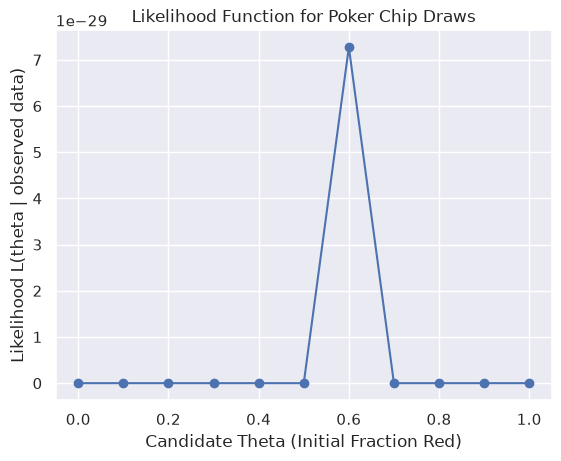

In [59]:
import random
import math

random.seed(42) # Set a seed for reproducible random draws

# --- Simulation Setup ---
TOTAL_CHIPS = 100
TRUE_PROPORTION = 0.6 # The actual proportion we are trying to estimate
N_DRAWS = 100 # How many chips we draw in our experiment


# Function to simulate drawing k chips without replacement
def draw_chips(initial_frac_red, total_chips, k):
    n_red = int(initial_frac_red * total_chips)
    n_green = total_chips - n_red
    if n_red < 0 or n_green < 0: # Basic error check
        raise ValueError("Invalid initial fraction leads to negative chip counts")
    if k > total_chips:
        raise ValueError("Cannot draw more chips than are in the bag")
    bag = ['red'] * n_red + ['green'] * n_green
    # random.sample simulates drawing without replacement
    return random.sample(bag, k=k)

# --- Likelihood Calculation ---
# Function to calculate probability of a single draw outcome
def prob_single_draw(outcome, current_n_red, current_total):
    if current_total <= 0: return 0 # Avoid division by zero
    if outcome == 'red':
        return current_n_red / current_total
    else: # outcome == 'green'
        return (current_total - current_n_red) / current_total

# Function to calculate the likelihood L(theta|x) for a sequence of draws
def calculate_likelihood_sequence(observed_draws, initial_frac_red_guess, total_chips):
    likelihood = 1.0
    current_n_red = int(initial_frac_red_guess * total_chips)
    current_n_green = total_chips - current_n_red
    current_total = total_chips

    if current_n_red < 0 or current_n_green < 0: # Check guess validity
         return 0 # Assign 0 likelihood if guess is impossible

    for draw_outcome in observed_draws:
        prob = prob_single_draw(draw_outcome, current_n_red, current_total)
        likelihood *= prob

        # If likelihood becomes zero, impossible sequence for this guess, stop early
        if likelihood == 0: break

        # Update counts for the next draw (without replacement)
        if draw_outcome == 'red':
            current_n_red -= 1
        else:
            current_n_green -= 1
        current_total -= 1

        # Check if counts became inconsistent (e.g., negative) - means initial guess was impossible
        if current_n_red < 0 or current_n_green < 0:
            return 0 # Assign 0 likelihood if sequence becomes impossible

    return likelihood


# --- Run Experiment and MLE ---
# Step 1: Perform the experiment (draw chips using the TRUE_PROPORTION)
observed_sequence = draw_chips(TRUE_PROPORTION, TOTAL_CHIPS, N_DRAWS)
print(f"Observed sequence (first 20): {observed_sequence[:20]}") # Optional check
#print(f"Number of red drawn: {observed_sequence.count('red')}, Number of green drawn: {observed_sequence.count('green')}")

# Step 2: Calculate likelihood for different candidate thetas (initial proportions)
candidate_thetas = [x / 10.0 for x in range(11)] # Proportions from 0.0 to 1.0
likelihoods = [calculate_likelihood_sequence(observed_sequence, theta_guess, TOTAL_CHIPS)
               for theta_guess in candidate_thetas]

# Step 3: Find the theta that maximizes the likelihood
mle_estimate_index = np.argmax(likelihoods)
mle_estimate = candidate_thetas[mle_estimate_index]

# --- Output Results ---
print("Candidate Thetas (Initial Red Fraction):", candidate_thetas)
print("Likelihoods for each Theta:\n", [f"{l:.3e}" for l in likelihoods]) # Format for readability
print(f"\nMaximum Likelihood Estimate (MLE) for theta: {mle_estimate}")
print(f"(True proportion was: {TRUE_PROPORTION})")

# Plot the likelihood function
plt.figure()
plt.plot(candidate_thetas, likelihoods, 'bo-')
plt.xlabel("Candidate Theta (Initial Fraction Red)")
plt.ylabel("Likelihood L(theta | observed data)")
plt.title("Likelihood Function for Poker Chip Draws")
plt.grid(True)
plt.show()

<div class="optional">

In this run, the likelihood is highest when the assumed initial proportion $\theta$ is 0.6, which matches the true proportion used to generate the data. (In fact, since we drew *all* 100 chips, the observed sequence contains exactly 60 red chips: every other candidate $\theta$ is impossible and has likelihood exactly zero. With fewer draws several candidates have non-zero likelihood, and the maximum need not sit at the true value - see the homework.) This demonstrates how MLE uses the observed data to find the parameter value that best explains what we saw. Note how small the likelihood values are, highlighting why working with log-likelihoods is often preferred in practice, especially with more data points.

</div>

<div class="advanced">

## Maximum a posteriori estimation (MAP; the Bayesian alternative to MLE) [\*\*]

We saw that Maximum Likelihood Estimation (MLE) finds the parameters $\theta$ that make our observed data $\mathbf{x}$ most probable. MLE is often considered a *frequentist* approach because it focuses solely on the likelihood derived from the data, without incorporating any prior beliefs about the parameters.

When data is limited, or when we *do* have some prior knowledge about plausible parameter values, a *Bayesian* approach called **Maximum A Posteriori (MAP) estimation** can be useful.

Instead of maximising the likelihood $P(\mathbf{x} | \theta)$, MAP aims to maximise the **posterior probability** $P(\theta | \mathbf{x})$. This is the probability of the parameters $\theta$ *given* the observed data $\mathbf{x}$. We find this using Bayes' Theorem:

$$P(\theta | \mathbf{x}) = \frac{P(\mathbf{x} | \theta) P(\theta)}{P(\mathbf{x})}$$

Here:
* $P(\mathbf{x} | \theta)$ is the **likelihood** (same as in MLE).
* $P(\theta)$ is the **prior probability** distribution of the parameters. This crucial term represents our beliefs about $\theta$ *before* seeing the data $\mathbf{x}$.
* $P(\mathbf{x})$ is the **evidence** (probability of the data).
* $P(\theta | \mathbf{x})$ is the **posterior probability** (our updated beliefs about $\theta$ *after* seeing the data).

<br>

**Finding the MAP Estimate:**

The MAP estimate, $\hat{\theta}_{MAP}$, is the value of $\theta$ that maximises the posterior probability:

$$\hat{\theta}_{MAP} = \underset{\theta}{\operatorname{arg\,max}} \, P(\theta | \mathbf{x}) = \underset{\theta}{\operatorname{arg\,max}} \, \frac{P(\mathbf{x} | \theta) P(\theta)}{P(\mathbf{x})}$$

Notice that the denominator, $P(\mathbf{x})$, doesn't depend on $\theta$. So, maximising the whole fraction is equivalent to maximising just the numerator:

$$\hat{\theta}_{MAP} = \underset{\theta}{\operatorname{arg\,max}} \, [ P(\mathbf{x} | \theta) P(\theta) ]$$

In words: the MAP estimate finds the parameters $\theta$ that maximise the product of the likelihood and the prior probability.

<br>

**Connection to MLE:**

* If we choose a **uniform prior** for $P(\theta)$ (meaning we assume all parameter values are equally likely *before* seeing the data), then $P(\theta)$ is just a constant. In this case, maximising $P(\mathbf{x} | \theta) P(\theta)$ becomes equivalent to maximising just the likelihood $P(\mathbf{x} | \theta)$.
* Therefore, **MAP estimation with a uniform prior reduces to MLE**.

MAP allows us to incorporate prior knowledge, which can be particularly helpful when we don't have much data. MLE is simpler when we have no prior knowledge or a very large amount of data (where the likelihood term tends to dominate the prior anyway).

*(Just like with MLE, in practice, MAP estimation is often done by maximising the log of the posterior, $\log P(\mathbf{x} | \theta) + \log P(\theta)$, or minimising its negative).*

*(Further reading:*
* *<https://machinelearningmastery.com/maximum-a-posteriori-estimation/>*
* *<https://stats.stackexchange.com/questions/95898/mle-vs-map-estimation-when-to-use-which>)*

</div>

<div class="optional">

## Revisiting linear regression from a probabilistic perspective [\*]

We've seen classification from a probabilistic perspective - let's do the same with regression.
    
In Lecture 5, we looked at **linear regression** as a way to fit a straight line (or more generally, a linear model) to data points. We approached it by finding the model parameters (like slope and intercept) that **minimised the sum of squared errors** (as well as some other error norms) between the model's predictions and the actual data points.

<br>

Recall that standard linear regression can be written as 

$$y(x) := \beta_0 + \beta_1 x$$

where we need to find the best free parameters $\beta_0$ and $\beta_1$ (I used $m$ and $c$ for slope and intercept previously).


<br>
    
However, this way of writing our "model" does not explicitly account for, i.e. provide a representation of, the inevitable errors that occur when our "model" cannot exactly describe all of the given data.

To do this, we can instead write linear regression in the form

$$
y(x) := \beta_0 + \beta_1 x + \epsilon
$$
    
where $\epsilon$ represents the difference (or residuals) between the actual observed value $y$ and the value predicted by the linear part $\beta_0 + \beta_1 x$. This $\epsilon$ is treated as a **random variable**, representing the uncertainty or noise in the relationship or measurement.

Because $\epsilon$ is random, for a given input $x$, the output $y$ also becomes a random variable.
    
Considered another way, for a fixed/given $x$, $y(x)$ can be considered a random variable due to the $\epsilon$ term.

<br>

    
   
**Assumptions about the Error Term ($\epsilon$):**

To connect this probabilistic view back to the least-squares method, we typically make some standard assumptions about the error term $\epsilon$:
1.  **Independence:** The errors $\epsilon_i$ for different data points $(x_i, y_i)$ are independent of each other.
2.  **Identically Distributed:** All errors $\epsilon_i$ are drawn from the *same* probability distribution  (e.g. same mean and variance).
3.  **Zero Mean:** The average value of the error is zero. This means the linear model $\beta_0 + \beta_1 x$ represents the *average* trend of $y$ given $x$.
4.  **Constant Variance (Homoscedasticity):** The spread (variance) of the error term, $\text{Var}(\epsilon_i) = \sigma^2$, is the same for all values of $x$.
5.  **(Commonly) Normality:** The errors $\epsilon_i$ follow a **normal (Gaussian) distribution** with mean 0 and variance $\sigma^2$. We write this as $\epsilon_i \sim \mathcal{N}(0, \sigma^2)$.

<br>

Hence, under these assumptions (especially normality), the random variable $y(x)$ ($y$, given an input $x$) follows a normal distribution with a mean of $\bar{y}$ and standard deviation $\sigma$, where the mean is given by $\bar{y} = \beta_0 + \beta_1 x$, and a variance $\sigma^2$, in shorthand:
    
$$y | x \sim \mathcal{N}(\beta_0 + \beta_1 x, \sigma^2)$$
    


*(Note: Linear regression can be extended to multiple input features $x_1, x_2, \ldots, x_n$: $y = \beta_0 + \beta_1 x_1 + \ldots + \beta_n x_n + \epsilon$. The probabilistic interpretation still applies).*
    


</div>

<div class="advanced">

### Maximum likelihood estimation for linear regression [\*\*]

Notice therefore that we have a model for our data with three unknown parameters: $\beta_0$, $\beta_1$ and $\sigma$.

Maximum likelihood estimation represents an approach to find the $\beta$ and $\sigma$ parameters, that maximises the likelihood


$$L(\theta | \mathbf{x}, \mathbf{y}) = P(\mathbf{y} \, | \, \mathbf{x}, \theta)$$

where $\theta = (\beta_0, \beta_1, \sigma^2)$, and where the mean of the distribution is given 
by $\bar{y} = \beta_0 + \beta_1 x$.

<br>

In this case, assuming a normal distribution (so the maths below makes use of the Gaussian expression), the likelihood for observation/data point $i$, i.e. ($x_{(i)}$, $y_{(i)}$), is

$$\frac{1}{\sigma\sqrt{2\pi}}e^{-\frac{1}{2}\frac{(y_{(i)} - \bar{y})^2}{\sigma^2}}
= \frac{1}{\sigma\sqrt{2\pi}}e^{-\frac{1}{2}\frac{(y_{(i)} - \beta_1 x_{(i)} - \beta_0)^2}{\sigma^2}}$$

and thus

$$L(\beta_0, \beta_1, \sigma^2) := \prod\limits_{i=1}^{n}\frac{1}{\sigma\sqrt{2\pi}}e^{-\frac{1}{2}\frac{(y_{(i)} - \beta_1 x_{(i)} - \beta_0)^2}{\sigma^2}}
 = \left(\frac{1}{{2\pi\sigma^2}}\right)^{n/2}e^{-\frac{1}{2\sigma^2}\sum\limits_{i=1}^{n}(y_{(i)} - \beta_1 x_{(i)} - \beta_0)^2}$$

<br> 

As above, log likelihoods are easier to work with, and so in this case of linear regression with our assumptions over the errors, we seek to minimise

\begin{align*}
-\log L(\beta_0, \beta_1, \sigma^2) 
& = - \log\left(\left(\frac{1}{2\pi\sigma^2}\right)^{n/2}e^{-\frac{1}{2\sigma^2}\sum\limits_{i=1}^{n}(y_{(i)} - \beta_1 x_{(i)} - \beta_0)^2}\right)\\
& = \frac{1}{2\sigma^2}\sum\limits_{i=1}^{n}(y_{(i)} - \beta_1 x_{(i)} - \beta_0)^2 + \frac{n}{2}\log(2\pi\sigma^2) 
\end{align*}

To maximise $\log L$ with respect to $\beta_0$ and $\beta_1$ (for a fixed $\sigma^2$), we need to **minimise** the term:
$$\sum_{i=1}^{n}(y_{(i)} - (\beta_0 + \beta_1 x_{(i)}))^2$$

This is exactly the **sum of squared errors** that the ordinary least-squares method minimises!    
    
<br>
    
**Conclusion:** Maximising the likelihood of the parameters for linear regression under the assumption of **normally distributed errors** is **equivalent** to minimising the sum of squared errors. This provides a probabilistic justification for the least-squares method.
    
See also
    
- <https://stats.stackexchange.com/questions/253345/relationship-between-mle-and-least-squares-in-case-of-linear-regression/254003>

- <https://stats.stackexchange.com/questions/143705/maximum-likelihood-method-vs-least-squares-method>

- <https://stats.stackexchange.com/questions/12562/equivalence-between-least-squares-and-mle-in-gaussian-model>
  
    
    

    
<br>
    
**Other assumptions on the error**
    
This argument demonstrates that the L2-norm (RMSE) 'least squares' method is mathematically equivalent to assuming our data's error ($\epsilon$) follows a Gaussian (Normal) distribution. 
We've previously seen examples of regression minimising other norms. 
It turns out that the result we get from minimising the L1-norm (MAE) method we saw in lecture 4 is what we get if we assume our errors follow a Laplace distribution, which is less sensitive to outliers than a Gaussian
    <https://ai.stackexchange.com/questions/42792/why-is-laplace-distribution-less-sensitive-to-outliers-than-normal-distribution>
    
</div>

<div class="advanced">

### Linear regression on the Iris dataset [\*\*]

Can we use linear regression to predict one of the features of the flowers in the Iris dataset, the sepal length say,  using the other columns? 
    
This is an example of there being multiple variables in linear regression!

<br>
    
The following code shows how you might do this using scikit-learn.

[Don't panic - you will cover scikit-learn more in future modules, so feel free to ignore this for now.]

</div>

Model Evaluation:
 Mean Absolute Error (MAE): 0.2596 cm
 Mean Squared Error (MSE): 0.1017 cm^2
 Root Mean Squared Error (RMSE): 0.3190 cm


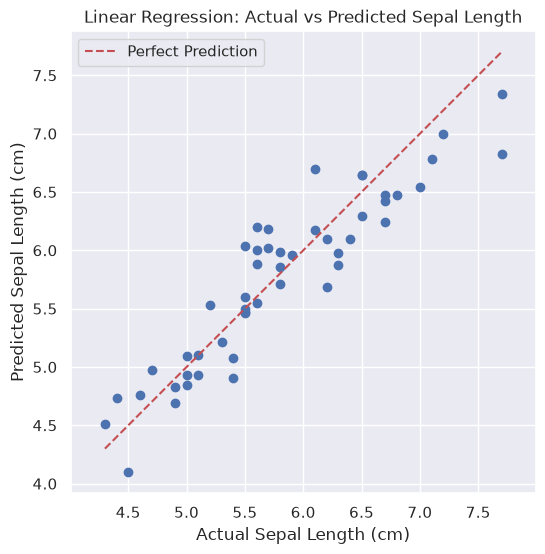

In [60]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error


# Preparing the data - remove sepal length from the data and call the result X - the features
X = irisdf.drop(labels = 'sepal length (cm)', axis= 1)
# y is the sepal length - the target
y = irisdf['sepal length (cm)']

# --- Split Data ---
# Split into training (to build the model) and testing (to evaluate it) sets
# test_size=0.33 means 33% for testing, 67% for training
# random_state ensures the split is the same each time we run the code
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size= 0.33, random_state= 101)

# --- Train Model ---
# Create a Linear Regression model instance
lr = LinearRegression()
# Train the model using the training data
lr.fit(X_train, y_train)

# --- Make Predictions ---
# Use the trained model to predict sepal length for the test features
pred = lr.predict(X_test)

# --- Evaluate Model ---
print('Model Evaluation:')
# MAE: Average absolute difference between predicted and actual values
print(f' Mean Absolute Error (MAE): {mean_absolute_error(y_test, pred):.4f} cm')
# MSE: Average squared difference
print(f' Mean Squared Error (MSE): {mean_squared_error(y_test, pred):.4f} cm^2')
# RMSE: Square root of MSE, in the original units (cm)
print(f' Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, pred)):.4f} cm')

# --- Visualize Predictions vs Actual ---
plt.figure(figsize=(6, 6))
# Scatter plot of actual (y_test) vs predicted (pred) values
plt.scatter(y_test, pred)
# Add a line y=x for reference (perfect prediction)
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], '--r', label='Perfect Prediction')
plt.xlabel('Actual Sepal Length (cm)')
plt.ylabel('Predicted Sepal Length (cm)')
plt.title('Linear Regression: Actual vs Predicted Sepal Length')
plt.legend()
plt.grid(True)
plt.axis('equal') # Ensure x and y axes have the same scale
plt.show()

<div class="advanced">

The scatter plot shows the model's predictions against the actual values. Points close to the red dashed line indicate accurate predictions. The MAE/RMSE gives an average sense of the prediction error (around 0.2-0.3 cm in this case).

    
##### Warning
In the previous linear regression example, we used the _target_ column as a predictor (i.e. an input to the model) to predict sepal length. 

The target column contains numerical values (0, 1 and 2) to represent something that is inherently not numerical (species of a flower). 

Using a number to represent a category might be acceptable if there are only two categories (e.g. Male/Female), but for more than two categories it might not make sense. For example, using the number 0 to represent Iris setosa, 1 to represent Iris versicolor, and 2 to represent Iris virginica implies that in some notional sense, the _distance_ between Iris setosa and Iris virginica is twice that of the distance between Iris setosa and Iris versicolor. 

This is, of course, not true. A better way would have been [one-hot encoding](https://en.wikipedia.org/wiki/One-hot#Machine_learning_and_statistics). 
Here, we replace a single column with three different categorical values (setosa/versicolor/virginica) with three columns, one for each possible value. Only one of these three columns will ever contain a 1, while the other two contain a 0. 

### Exercise
Repeat the linear regression example, using [pandas.get_dummies](https://pandas.pydata.org/docs/reference/api/pandas.get_dummies.html) to convert the target column into three indicator columns. 

</div>

<div class="optional">

## Back to classification (via logistic regression) [\*]

Recall the pairwise scatter plots for the Iris dataset:

</div>

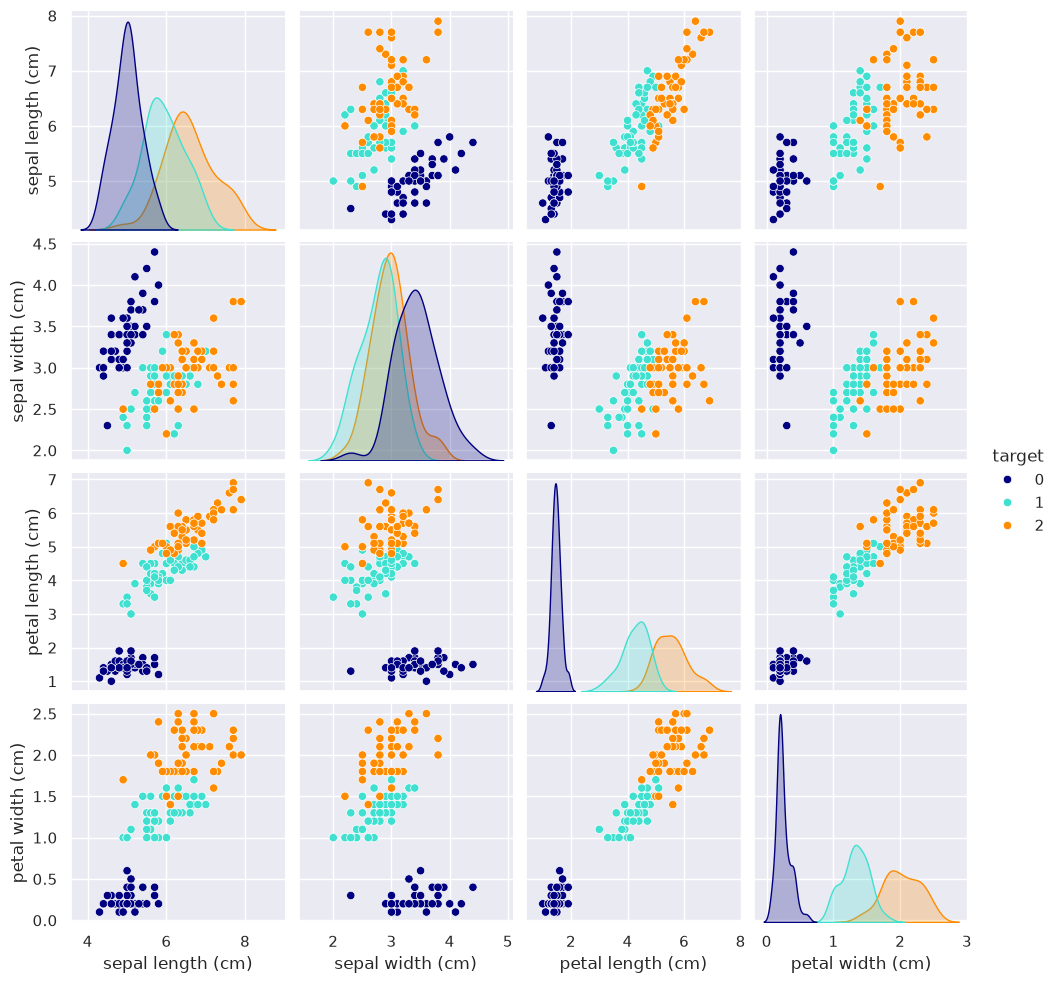

In [61]:
sns.set() # Apply seaborn default styles

# Create a pair plot, coloring points by the 'target' (species) column
# We exclude the 'target' column itself from the pairwise plots (vars=...)
sns.pairplot(irisdf, vars=irisdf.columns[:-1], hue='target',
             palette={0: 'navy', 1: 'turquoise', 2: 'darkorange'}) # Optional: specify colors


<div class="optional">

In these scatterplots, the colours represent the species of the flower. We can see that the target=0 (Setosa) species is clearly separated from the other two. 

In most of these scatter plots, a straight line through the scatter plot could divide the plotted area into a region where the species is 0 (Setosa) and a region where the species is not 0 (i.e. Versicolour or Virginica). 

The species of any new point could then be predicted based on which region the new point falls in. 

</div>

<div class="optional">
    
    
Recall in the Naive Bayes section, we built a classifier to predict the Iris species based on its features. We used Bayes' theorem and assumed the features followed normal distributions within each class.

Let's explore another common approach to classification called **Logistic Regression**. Despite its name, logistic regression is used for **classification**, not regression (predicting continuous values).

<br>

**Motivation: Why not just use Linear Regression for Classification?**

We could try using linear regression (like we did to predict sepal length) to predict a class label. For a *binary* classification problem (two classes, say 0 and 1), we could try to fit a line $y = \beta_0 + \beta_1 x_1 + \ldots + \beta_n x_n$. Perhaps we could predict class 1 if $y > 0.5$ and class 0 if $y \leq 0.5$.

However, there's a problem: the output of linear regression can range from $-\infty$ to $+\infty$. This doesn't naturally fit with class labels (like 0 or 1) or probabilities (which must be between 0 and 1).

</div>

<div class="optional">

### Classification via logistic regression [\*]

Logistic regression solves this by using the linear model *inside* a function that squashes the output into the range $[0, 1]$. This output can then be interpreted as a probability.   

</div>

<div class="optional">
    
### Sigmoid functions ... the logistic function [\*]

The function used to squash the output is typically a **sigmoid function**, which has an "S" shape. A very common sigmoid is the **logistic function** (also just called the [**sigmoid function**](https://en.wikipedia.org/wiki/Sigmoid_function) in many ML contexts):

$$\sigma(z) = \frac{1}{1 + e^{-z}}$$
    


<img src="images/activation_sigmoid.png" />

Image by [dvgodoy](https://github.com/dvgodoy/dl-visuals)/[CC-BY](https://creativecommons.org/licenses/by/4.0/)

<br>

The plot above shows the sigmoid function in black, and its derivative in red. 

As you can see from its graph, no matter what value $z$ (the output of the linear part) takes (from $-\infty$ to $+\infty$), the output $\sigma(z)$ is always between 0 and 1.

* If $z$ is large and positive, $e^{-z}$ is close to 0, so $\sigma(z) \approx 1 / (1 + 0) = 1$.
* If $z$ is large and negative, $e^{-z}$ is very large, so $\sigma(z) \approx 0$.
* If $z = 0$, $e^{-z} = 1$, so $\sigma(z) = 1 / (1 + 1) = 0.5$.

*(See the homework for plotting this function and its derivative).*

</div>

<div class="optional">

### Classification using the logistic function and linear regression [\*]
    
The logistic regression model combines linear regression and the logistic function:

<br>  
    
1.  Calculate a score $z$ using a linear combination of the input features $x_1, \ldots, x_n$ (just like in linear regression):
    
    $$z = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \ldots + \beta_n x_n$$
    
    Here, $\beta_0, \beta_1, \ldots, \beta_n$ are the model parameters (weights and bias) that need to be learned from the data.

<br>   
    
2.  Pass this score $z$ through the logistic function $\sigma(\cdot)$ to get the output $y$:
    $$y = \sigma(z) = \frac{1}{1 + e^{-z}}$$

    
    
**Interpretation:**
    
For binary classification (classes 0 and 1), this output $y$ can be interpreted as the estimated **probability** that the input data belongs to class 1:
    
$$y = P(Y=1 | X=(x_1, \ldots, x_n))$$
    
The probability of belonging to class 0 is then simply $1 - y$.

**Prediction:** To make a class prediction, we typically set a threshold (often 0.5).
    
* If $y > 0.5$, predict class 1.
* If $y \leq 0.5$, predict class 0.

*(Note: Finding the best parameters $\beta_i$ for logistic regression usually involves techniques like Maximum Likelihood Estimation, often minimising a specific cost function called the log loss or cross-entropy, rather than minimising squared errors like in linear regression).*
    
</div>

<div class="optional">

### Interpretation as a simple neural network

With that, we have built perhaps the simplest **neural network** possible. Said another way, the logistic regression model can be viewed as a very simple **neural network**

See also <https://stackoverflow.com/questions/59580874/what-is-the-difference-between-logistic-regression-and-single-neuron-perceptron>

<br>
    
    
* The inputs $x_1, \ldots, x_n$ are fed into a single "neuron".

* The neuron computes the weighted sum $z = \beta_0 + \sum \beta_i x_i=b+w^Tx$ (where $\beta_0$ is the bias "b" and $\beta_i$ are the weights "w").

* This sum $z$ is then passed through an **activation function**, which in this case is the logistic (sigmoid) function $\sigma(z)$.
    
* The output $y = \sigma(z)$ is the network's prediction (the probability of class 1).

This forms the building block for more complex neural networks used in deep learning.
    
    
    

<img src="images/logistic_model.png" />

Image by [dvgodoy](https://github.com/dvgodoy/dl-visuals)/[CC-BY](https://creativecommons.org/licenses/by/4.0/)


</div>

<div class="optional">

### Comparison between Logistic Regression and Naive Bayes [\*]

* **Naive Bayes:** Models the likelihood $P(X|Y)$ and the prior $P(Y)$ separately, then uses Bayes' theorem. Relies on the (often incorrect) feature independence assumption. Can incorporate prior beliefs. Often works well even with small datasets.
    
    
* **Logistic Regression:** Directly models the posterior probability $P(Y|X)$. Doesn't assume feature independence, which can be an advantage if features are correlated. However, it doesn't directly incorporate prior beliefs in the same way. Often performs well with larger datasets or where features are not independent

</div>

<div class="advanced">
    
### An example  [\*\*]

Let's apply logistic regression to the Iris dataset, but simplify it to a binary classification problem first: distinguishing Iris Setosa (class 0) from the other two species (class 1 and 2 combined). We'll use scikit-learn's implementation.
    
</div>

In [62]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score



# --- Prepare Data for Binary Classification ---
X = iris['data']# Features
# Reduce the problem to a two-class classification problem, 
# for target=0 vs target>0 (1 or 2)
y = [int(x > 0) for x in iris['target']]

# --- Split Data ---
# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size= 0.33, random_state= 101)

# --- Train Model ---
# Create a Logistic Regression model instance
# Note: scikit-learn's LogisticRegression can handle multiclass problems too,
# but here we use it for the binary case we prepared.
lr_model = LogisticRegression(solver='liblinear') # Specify solver for potentially small dataset
# Train the model
lr_model.fit(X_train, y_train)

# --- Make Predictions ---
# Predict classes for the test set
pred = lr_model.predict(X_test)

# --- Evaluate Model ---
accuracy = accuracy_score(y_test, pred)
print(f"Accuracy of Logistic Regression (Setosa vs Others): {accuracy:.4f}")

Accuracy of Logistic Regression (Setosa vs Others): 1.0000


<div class="advanced">

The accuracy is 1.0 (or 100%)! This means the logistic regression model perfectly separated the Iris Setosa samples from the Versicolor and Virginica samples in the test set. Looking back at the pair plots, Setosa (class 0) is indeed linearly separable from the other two classes using the given features.

**Limitation & Extension:**
This example only solved a binary problem (Setosa vs. not Setosa). To handle the original 3-class problem directly with logistic regression, you can use techniques like:
* **One-vs-Rest (OvR):** Train separate binary classifiers (e.g., Class 0 vs Rest, Class 1 vs Rest, Class 2 vs Rest) and choose the class with the highest confidence.
* **Multinomial Logistic Regression (Softmax Regression):** A direct extension of logistic regression that handles multiple classes simultaneously by outputting a probability for each class. Scikit-learn's `LogisticRegression` often implements this automatically for multiclass targets.

*(Further reading on multinomial logistic regression: <https://en.wikipedia.org/wiki/Multinomial_logistic_regression>)*

and also <https://machinelearningmastery.com/multinomial-logistic-regression-with-python/>

</div>

## Other classification and regression models

In the next module (**Data Science & Machine Learning**) you will pick up the story on other classification and regression methods, such as:

- [Support vector machine](https://en.wikipedia.org/wiki/Support_vector_machine); for an example application to the Iris data set: <https://scikit-learn.org/stable/auto_examples/svm/plot_iris_svc.html>

- [k-nearest neighbour](https://en.wikipedia.org/wiki/K-nearest_neighbors_algorithm); for an example application to the Iris data set see: <https://medium.com/@avulurivenkatasaireddy/k-nearest-neighbors-and-implementation-on-iris-data-set-f5817dd33711>

- [Decision trees](https://en.wikipedia.org/wiki/Decision_tree_learning); for an example application to the Iris data set see: <https://scikit-learn.org/stable/modules/tree.html>

And in the module after that (**Deep Learning**) you will pick up the story of (deep) neural networks, e.g. for the Iris data set see: <https://www.kaggle.com/code/louisong97/neural-network-approach-to-iris-dataset/notebook>

### To mentimeter

# Summary

So what have we covered today?

1. A review of some introductory statistics.

2. A review of some probability concepts and theory.

3. In particular, conditional probabilities and Bayes theorem.

4. The use of probabilistic methods as a basis for some simple ML algorithms - including some examples of classification and regression.

**PCA** and its links to SVD: Note that a homework exercise involves PCA applied to the Iris data set. Recall that we mentioned in L3 that PCA (and related dimension reduction/data analysis techniques) is very important in data science & ML, and that it's closely related to the SVD.  The homework exercise points you to some further reading, but also walks you through performing PCA from "first principles", i.e. by starting from an SVD, and compares our result against what you can get in a few lines with libraries like Scikit-Learn (but without necessarily understanding what is actually going on).

## Feedback

<img src="images/feedback_qr.png" style="width: 25%">

[Or click here](https://forms.cloud.microsoft/Pages/ResponsePage.aspx?id=B3WJK4zudUWDC0-CZ8PTB7wCPgYswKVBuRjvHBJCboRURUxRR0kwWTZYWDhMQkhGRlZFVTVKWUpVVC4u)